# DJI OcuSync: an LTE modem without a cellular network

**OcuSync** is DJI's proprietary radio link between the drone and its controller: video down, control up, telemetry. There is no specification; everything known comes from reverse engineering. The best-understood piece is **DroneID**, a broadcast burst with the drone's and the pilot's coordinates that the drone sends every ~600 ms with the same modem (Schiller et al., *Drone Security and the Mysterious Case of DJI's DroneID*, NDSS 2023; the `proto17/dji_droneid` project). Its physical layer is almost a verbatim copy of the LTE 10 MHz downlink:

| | LTE, 10 MHz | DroneID / OcuSync 2 |
|---|---|---|
| sample rate, $N_\text{FFT}$, $\Delta f$ | 15.36 MHz, 1024, 15 kHz | **the same** |
| occupied subcarriers | 600 + empty DC | **the same** |
| CP, samples | 80 / 72 | 80 (first and last symbol) / 72 |
| symbols | 14 per 1 ms subframe, continuous stream | 9 per 643 µs burst, isolated bursts |
| synchronization | PSS (ZC-63 on 62 subcarriers) + SSS, once at network entry | two full-band ZC-601 (roots 600 and 147) in **every** burst |
| reference signals | CRS: every 6th subcarrier in 4 of 14 symbols | none of their own: the channel is estimated from the same ZC |
| channel code | turbo code, rate matching, Gold scrambler | **the same** turbo code ($K=1408$), the same rate matching to 7200 bits, Gold with $c_\text{init}=\texttt{0x12345678}$ |
| modulation | QPSK…256QAM by CQI | QPSK (DroneID); adaptive for video |

It looks as if DJI took an LTE modem together with its hardware (FFT, turbo-decoder trellises) and threw out everything a cellular network needs: cells, the scheduler, multiple access, licensed spectrum. What remains is a point-to-point link in the 2.4/5.8 GHz ISM bands, a burst that the receiver has to catch from scratch on an unknown frequency, and bandwidth adaptation to range.

Generations (per DJI and hobbyist measurements; details are uncertain): OcuSync 1.0 (2016, Mavic Pro) — 2.4 GHz; **2.0** (2019, Mavic 2, Mini 2) — 2.4/5.8 GHz, 1.4/10/20 MHz channels; **O3/O3+** (2021, DJI FPV, Air 2S, Mavic 3) — up to 40 MHz, 2 transmit and 4 receive antennas; **O4** (2023, Mini 4 Pro, Air 3) — up to 20 km under FCC rules.

**What is modelled.** The DroneID burst is reproduced exactly from the published reverse engineering, down to the bits. Less is public about the video link: it uses the same 15 kHz OFDM with ZC, but its MCS, pilots and repeats have not been worked out in detail. Sections 7–8 therefore treat the video link as a physical model, not a copy.

1. The burst: 9 symbols vs 14 · 2. Zadoff–Chu and the time–frequency link · 3. Synchronizing from scratch · 4. The air-to-ground channel · 5. Channel estimation without pilots · 6. The LTE turbo code with repeats · 7. Link budget and bandwidth adaptation · 8. The ISM band and frequency hopping

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from scipy.special import erfc
from scipy.integrate import quad
from scipy.stats import ncx2

%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

SEED = 1
FC_GHZ = 2.44              # carrier: 2.44 or 5.8 GHz
SNR_DB = 5                 # Es/N0 per subcarrier for the demos (sections 3, 5)
CFO_HZ = 23e3              # drone-vs-controller frequency offset (≈1.5 subcarriers)
K_RICE_DB = 10             # air-to-ground K-factor: direct ray / scatter
H_DRONE, H_RC = 120, 1.5   # drone and controller heights, m
EIRP_DBM = 20              # 20 — CE (Europe), 30 — FCC (US), 2.4 GHz
G_RX_DBI, NF_DB = 3, 6     # controller antenna gain and noise figure
TURBO_ITERS = 6
WIFI_DUTY = 0.3            # fraction of time each Wi-Fi network is busy (section 8)

rng = np.random.default_rng(SEED)

## Primitives: DroneID burst, ZC, LTE turbo code, rate matching, channels, receiver

In [2]:
# ---------- DroneID / OcuSync 2 burst numerology (10 MHz channel) ----------
FS, N_FFT, DF = 15.36e6, 1024, 15e3            # exactly LTE 10 MHz
N_SC = 600
SC_IDX = np.r_[-N_SC // 2:0, 1:N_SC // 2 + 1]  # DC subcarrier unused
CP_B = np.array([80, 72, 72, 72, 72, 72, 72, 72, 80])
N_SYM = len(CP_B)
ZC_SYM = {3: 600, 5: 147}                      # symbol index (0-based) → ZC root
DATA_SYM = [1, 2, 4, 6, 7, 8]
E_BITS = 2 * N_SC * len(DATA_SYM)              # 7200 QPSK bits per burst
K_TB = 1408; D_TB = K_TB + 4; N_INFO = K_TB - 24
L_BURST = int(CP_B.sum() + N_SYM * N_FFT)
SYM_OFF = np.r_[0, np.cumsum(CP_B[:-1] + N_FFT)]   # start of each symbol (with CP) from burst start

def crandn(shape, rng):
    return (rng.standard_normal(shape) + 1j * rng.standard_normal(shape)) / np.sqrt(2)

def zc(u, L=601):
    """Zadoff–Chu of length 601; the middle element (lands on DC) is dropped → 600 subcarriers."""
    n = np.arange(L)
    return np.delete(np.exp(-1j * np.pi * u * n * (n + 1) / L), L // 2)

def sym_starts(cp=CP_B):
    cp = np.asarray(cp)
    return np.cumsum(np.r_[0, cp[:-1] + N_FFT]) + cp

def ofdm_mod(X, cp=CP_B, sc=SC_IDX):
    """X (..., Nsym, Nsc) → samples (..., L). Unit power per subcarrier."""
    G = np.zeros(X.shape[:-1] + (N_FFT,), complex); G[..., sc % N_FFT] = X
    x = np.fft.ifft(G, axis=-1) * np.sqrt(N_FFT)
    return np.concatenate([np.concatenate([x[..., s, N_FFT - cp[s]:], x[..., s, :]], -1)
                           for s in range(X.shape[-2])], -1)

def ofdm_demod(y, start=0, cp=CP_B, full=False):
    """start is the burst start (scalar or one per row). full=True returns all 1024 bins."""
    idx = np.asarray(start)[..., None, None] + sym_starts(cp)[:, None] + np.arange(N_FFT)
    seg = np.take_along_axis(y[..., None, :], idx, -1) if np.ndim(start) else y[..., idx]
    Y = np.fft.fft(seg, axis=-1) / np.sqrt(N_FFT)
    return Y if full else Y[..., SC_IDX % N_FFT]

def qpsk(b):
    return ((1 - 2.0 * b[..., 0::2]) + 1j * (1 - 2.0 * b[..., 1::2])) / np.sqrt(2)

def qpsk_llr(z, n0):
    """LLR = ln P(0)/P(1) for equalized z with effective per-subcarrier noise n0"""
    s = 2 * np.sqrt(2) / n0
    return np.stack([s * z.real, s * z.imag], -1).reshape(z.shape[:-1] + (-1,))

# ---------- scrambler: LTE Gold-31 (36.211 §7.2) ----------
def gold_c(c_init, n, Nc=1600):
    x1 = np.zeros(Nc + n + 31, np.uint8); x2 = np.zeros_like(x1)
    x1[0] = 1; x2[:31] = (c_init >> np.arange(31)) & 1
    for i in range(Nc + n):
        x1[i + 31] = x1[i + 3] ^ x1[i]
        x2[i + 31] = x2[i + 3] ^ x2[i + 2] ^ x2[i + 1] ^ x2[i]
    return x1[Nc:Nc + n] ^ x2[Nc:Nc + n]
C_SCR = gold_c(0x12345678, E_BITS)             # seed recovered from firmware

# ---------- CRC24A (36.212 §5.1.1) as a GF(2)-linear map ----------
def crc_rows(L, poly=0x864CFB, n=24):
    """Row i is x^(24+L−1−i) mod g(x): CRC = a·M mod 2."""
    rows = np.zeros((L, n), np.int64); r = poly
    for j in range(L):
        rows[L - 1 - j] = (r >> np.arange(n - 1, -1, -1)) & 1
        r = ((r << 1) ^ (poly if (r >> (n - 1)) & 1 else 0)) & ((1 << n) - 1)
    return rows
CRC_M = crc_rows(N_INFO)
crc24a = lambda a: (a @ CRC_M) % 2

# ---------- LTE turbo code (36.212 §5.1.3) — same as in lte_sim / turbo_sim ----------
QPP = {40: (3, 10), 1408: (43, 88)}

def qpp(K):
    f1, f2 = QPP[K]
    i = np.arange(K, dtype=np.int64)
    return (f1 * i + f2 * i * i) % K

NXT = np.zeros((8, 2), int); PAR = np.zeros((8, 2), int); FB = np.zeros(8, int)
for s in range(8):
    s1, s2, s3 = (s >> 2) & 1, (s >> 1) & 1, s & 1
    FB[s] = s2 ^ s3
    for u in (0, 1):
        a = u ^ s2 ^ s3
        NXT[s, u] = (a << 2) | (s1 << 1) | s2
        PAR[s, u] = a ^ s1 ^ s3
PREV_S = np.zeros((8, 2), int); PREV_U = np.zeros((8, 2), int)
_c = np.zeros(8, int)
for s in range(8):
    for u in (0, 1):
        ns = NXT[s, u]; PREV_S[ns, _c[ns]] = s; PREV_U[ns, _c[ns]] = u; _c[ns] += 1

def rsc_encode(u):
    B, K = u.shape
    s = np.zeros(B, int); z = np.empty((B, K), int)
    for k in range(K):
        z[:, k] = PAR[s, u[:, k]]; s = NXT[s, u[:, k]]
    xt = np.empty((B, 3), int); zt = np.empty((B, 3), int)
    for k in range(3):
        ut = FB[s]; xt[:, k] = ut; zt[:, k] = PAR[s, ut]; s = NXT[s, ut]
    return z, xt, zt

def turbo_encode_d(u):
    """u (B,K) → d (B, 3, K+4): three streams with tails laid out as in 36.212"""
    z1, x1, t1 = rsc_encode(u)
    z2, x2, t2 = rsc_encode(u[:, qpp(u.shape[1])])
    d0 = np.c_[u, x1[:, 0], t1[:, 1], x2[:, 0], t2[:, 1]]
    d1 = np.c_[z1, t1[:, 0], x1[:, 2], t2[:, 0], x2[:, 2]]
    d2 = np.c_[z2, x1[:, 1], t1[:, 2], x2[:, 1], t2[:, 2]]
    return np.stack([d0, d1, d2], 1)

def d_to_L(Ld):
    """LLRs of streams d (B,3,K+4) → decoder layout: triples [x, z, z'] and tails [x₁ᵗ, z₁ᵗ, x₂ᵗ, z₂ᵗ]."""
    K = Ld.shape[-1] - 4; d0, d1, d2 = Ld[:, 0], Ld[:, 1], Ld[:, 2]
    tri = np.stack([d0[:, :K], d1[:, :K], d2[:, :K]], -1).reshape(len(Ld), -1)
    return np.concatenate([tri, np.c_[d0[:, K], d2[:, K], d1[:, K + 1]], np.c_[d1[:, K], d0[:, K + 1], d2[:, K + 1]],
                           np.c_[d0[:, K + 2], d2[:, K + 2], d1[:, K + 3]], np.c_[d1[:, K + 2], d0[:, K + 3], d2[:, K + 3]]], 1)

def _maxstar(a, b, exact):
    m = np.maximum(a, b)
    return m + np.log1p(np.exp(-np.abs(a - b))) if exact else m

def bcjr(Ls, Lp, La, Lst, Lpt, exact):
    B, K = Ls.shape
    Lx = np.concatenate([Ls + La, Lst], 1).T; Lz = np.concatenate([Lp, Lpt], 1).T
    zs = 1 - 2 * PAR; xs = np.array([1, -1])
    g = 0.5 * (Lx[:, :, None, None] * xs + Lz[:, :, None, None] * zs)
    T = K + 3
    al = np.full((T + 1, B, 8), -1e9); al[0, :, 0] = 0
    for t in range(T):
        a = _maxstar(al[t][:, PREV_S[:, 0]] + g[t][:, PREV_S[:, 0], PREV_U[:, 0]],
                     al[t][:, PREV_S[:, 1]] + g[t][:, PREV_S[:, 1], PREV_U[:, 1]], exact)
        al[t + 1] = a - a.max(1, keepdims=True)
    be = np.full((B, 8), -1e9); be[:, 0] = 0
    Lout = np.empty((B, K))
    red = (lambda v: np.logaddexp.reduce(v, 1)) if exact else (lambda v: v.max(1))
    for t in range(T - 1, -1, -1):
        if t < K:
            m = al[t][:, :, None] + g[t] + be[:, NXT]
            Lout[:, t] = red(m[:, :, 0]) - red(m[:, :, 1])
        b = _maxstar(be[:, NXT[:, 0]] + g[t][:, :, 0], be[:, NXT[:, 1]] + g[t][:, :, 1], exact)
        be = b - b.max(1, keepdims=True)
    return Lout

def turbo_decode(L, K, iters=TURBO_ITERS, exact=False, scale=0.7):
    """Two BCJRs exchange extrinsic LLRs through the QPP; max-log ×0.7 as in lte_sim."""
    m = L[:, :3 * K].reshape(-1, K, 3); t = L[:, 3 * K:]
    Ls, Lp1, Lp2 = m[..., 0], m[..., 1], m[..., 2]
    pi = qpp(K); ipi = np.argsort(pi)
    sc = 1.0 if exact else scale
    La = np.zeros_like(Ls)
    for it in range(iters):
        L1 = bcjr(Ls, Lp1, La, t[:, 0:3], t[:, 3:6], exact)
        Le1 = sc * (L1 - Ls - La)
        L2 = bcjr(Ls[:, pi], Lp2, Le1[:, pi], t[:, 6:9], t[:, 9:12], exact)
        La = (sc * (L2 - Ls[:, pi] - Le1[:, pi]))[:, ipi]
    return (L2[:, ipi] < 0).astype(int)

# ---------- LTE rate matching (36.212 §5.1.4.1): sub-block interleaver + circular buffer ----------
P_COL = np.array([0, 16, 8, 24, 4, 20, 12, 28, 2, 18, 10, 26, 6, 22, 14, 30,
                  1, 17, 9, 25, 5, 21, 13, 29, 3, 19, 11, 27, 7, 23, 15, 31])

def rm_index(D, E, rv=0):
    """Indices into the concatenation [d0, d1, d2] (length 3D) for each of the E transmitted bits."""
    C = 32; R = -(-D // C); Kp = R * C
    y = np.r_[-np.ones(Kp - D, int), np.arange(D)]               # −1 marks NULL fillers
    v01 = y.reshape(R, C)[:, P_COL].T.ravel()                    # column permutation, read column-wise
    k = np.arange(Kp)
    v2 = y[(P_COL[k // R] + C * (k % R) + 1) % Kp]
    tag = lambda v, s: np.where(v < 0, -1, v + s * D)
    w = np.r_[tag(v01, 0), np.stack([tag(v01, 1), tag(v2, 2)], 1).ravel()]
    k0 = R * (2 * -(-len(w) // (8 * R)) * rv + 2)
    w = np.roll(w, -k0); w = w[w >= 0]
    return np.resize(w, E)                                       # wrap around until E bits
RM_IDX = rm_index(D_TB, E_BITS)

# ---------- DroneID transmitter ----------
ZC_REF = {s: zc(r) for s, r in ZC_SYM.items()}

def drone_tx(B, rng):
    """CRC24A → turbo K=1408 → rate matching to 7200 bits → Gold scrambler → QPSK → 9×600 grid"""
    a = rng.integers(0, 2, (B, N_INFO))
    e = turbo_encode_d(np.c_[a, crc24a(a)]).reshape(B, -1)[:, RM_IDX] ^ C_SCR
    X = np.zeros((B, N_SYM, N_SC), complex)
    X[:, DATA_SYM] = qpsk(e).reshape(B, len(DATA_SYM), N_SC)
    X[:, 0] = qpsk(rng.integers(0, 2, (B, 2 * N_SC)))           # extra symbol, ignored by the receiver
    for s, z in ZC_REF.items():
        X[:, s] = z
    return a, e, X

# ---------- channels ----------
EVA = (np.array([0, 30, 150, 310, 370, 710, 1090, 1730, 2510]) * 1e-9, [0, -1.5, -1.4, -3.6, -0.6, -9.1, -7, -12, -16.9])

def taps(kind, rng, batch=(), K_db=K_RICE_DB):
    """A channel that is static over the burst: coefficients g (*batch, P) and delays in samples.
    'a2g' — air-to-ground: a specular part (direct ray + ground reflection; at 120 m altitude and ≥1 km range
            they are a few ns apart — one sample) + diffuse scatter with an exponential profile, τ_rms ≈ 65 ns, share 1/(K+1).
    'eva' — Rayleigh 3GPP EVA (terrestrial LTE) for comparison. 'awgn' — H = 1."""
    if kind == "awgn":
        return np.ones(batch + (1,), complex), np.array([0])
    if kind == "eva":
        p = 10 ** (np.array(EVA[1]) / 10); p /= p.sum()
        return np.sqrt(p) * crandn(batch + (len(p),), rng), np.round(EVA[0] * FS).astype(int)
    K = 10 ** (K_db / 10)
    p = np.exp(-np.arange(6.0)); p = p / p.sum() / (K + 1)
    g = np.sqrt(p) * crandn(batch + (6,), rng)
    g[..., 0] += np.sqrt(K / (K + 1)) * np.exp(2j * np.pi * rng.random(batch))
    return g, np.arange(6)

def freq_resp(g, d, sc=SC_IDX):
    return g @ np.exp(-2j * np.pi * np.outer(d, sc) / N_FFT)

def apply_channel(x, g, d):
    y = np.zeros(x.shape, complex)
    for k, dk in enumerate(d):
        y[..., dk:] += g[..., k, None] * x[..., :x.shape[-1] - dk]
    return y

def air(X, kind, snr_db, rng, cfo_hz=CFO_HZ, pad=(200, 600), ret_h=False):
    """grid → OFDM → channel → CFO → noise; the burst starts at a random t0 ∈ [pad0, pad1)"""
    B = len(X); x = ofdm_mod(X)
    t0 = rng.integers(*pad, B)
    L = pad[1] + x.shape[-1] + 100
    buf = np.zeros((B, L), complex)
    np.put_along_axis(buf, t0[:, None] + np.arange(x.shape[-1]), x, -1)
    g, d = taps(kind, rng, (B,))
    cfo = np.broadcast_to(cfo_hz, (B,))[:, None]
    y = apply_channel(buf, g, d) * np.exp(2j * np.pi * cfo / FS * np.arange(L))
    n0 = 10 ** (-snr_db / 10)
    y = y + np.sqrt(n0) * crandn(y.shape, rng)
    return (y, t0, freq_resp(g, d)) if ret_h else (y, t0)

# ---------- receiver ----------
def cp_sync(y):
    """CP synchronization (van de Beek): Γ(θ) = Σ over all 9 prefixes of r*[n]·r[n+N].
    θ̂ = argmax |Γ|/E, fractional offset ε̂ = ∠Γ(θ̂)/2π in subcarriers (range ±0.5)."""
    p = np.conj(y[..., :-N_FFT]) * y[..., N_FFT:]
    e = 0.5 * (np.abs(y[..., :-N_FFT])**2 + np.abs(y[..., N_FFT:])**2)
    z = np.zeros(p.shape[:-1] + (1,))
    cp_, ce = np.concatenate([z, np.cumsum(p, -1)], -1), np.concatenate([z, np.cumsum(e, -1)], -1)
    th = np.arange(p.shape[-1] - SYM_OFF[-1] - CP_B[-1] + 1)
    G = sum(cp_[..., th + o + c] - cp_[..., th + o] for o, c in zip(SYM_OFF, CP_B))
    E = sum(ce[..., th + o + c] - ce[..., th + o] for o, c in zip(SYM_OFF, CP_B))
    M = np.abs(G) / (E + 1e-12)
    i = np.argmax(M, -1)
    return i, np.angle(np.take_along_axis(G, i[..., None], -1)[..., 0]) / (2 * np.pi), M

def int_cfo(Yf, syms=(3, 5), Q=4, win=24):
    """Integer offset q from the ZC symbols: for hypothesis q the impulse response is h_q = IFFT(Y[k+q]·ZC*[k]).
    Metric: max over lags within ±win of the product of |h_q| over the chosen ZC symbols."""
    qs = np.arange(-Q, Q + 1); lag = np.r_[0:win, N_FFT - win:N_FFT]; m = []
    for q in qs:
        h = 1.0
        for s in syms:
            H = np.zeros(Yf.shape[:-2] + (N_FFT,), complex)
            H[..., SC_IDX % N_FFT] = Yf[..., s, (SC_IDX + q) % N_FFT] * np.conj(ZC_REF[s])
            h = h * np.abs(np.fft.ifft(H, axis=-1)[..., lag])
        m.append(h.max(-1))
    m = np.stack(m, -1)
    return qs[np.argmax(m, -1)], m

KEEP = (40, 12)     # how many taps of the 600-point impulse response to keep: delays 0…39 and "negative" −12…−1 (the FFT window starts early)

def dft_denoise(H, keep=KEEP):
    """DFT denoising: impulse response = IFFT(H over 600 subcarriers); everything outside the window is noise and is zeroed. Noise drops by 600/(K₁+K₂)."""
    h = np.fft.ifft(H, axis=-1)
    h[..., keep[0]:N_SC - keep[1]] = 0
    return np.fft.fft(h, axis=-1)

def zc_channel(Y, keep=KEEP):
    """H from the two ZC symbols: LS on all 600 subcarriers (+ DFT denoising if keep), phase advance φ per symbol, noise N0."""
    H3r, H5r = Y[..., 3, :] * np.conj(ZC_REF[3]), Y[..., 5, :] * np.conj(ZC_REF[5])
    H3, H5 = (dft_denoise(H3r, keep), dft_denoise(H5r, keep)) if keep else (H3r, H5r)
    phi = np.angle(np.sum(H5 * np.conj(H3), -1)) / 2
    a = np.exp(1j * phi)[..., None]
    Hm = 0.5 * (H3 * a + H5 / a)                                    # referred to symbol 4
    n0 = np.mean(np.abs(H3r * a - H5r / a)**2, -1) / 2              # from raw LS: the difference of two estimates is pure noise
    s = np.array(DATA_SYM)
    Hs = Hm[..., None, :] * np.exp(1j * phi[..., None, None] * (s[:, None] - 4))
    return Hs, phi, n0, H3

def decode_e(Lc, iters=TURBO_ITERS, rm=RM_IDX):
    """LLRs of transmitted bits (descrambled) → inverse rate matching (sum the repeats) → turbo → CRC."""
    B = len(Lc); Ld = np.zeros((3 * D_TB, B))
    np.add.at(Ld, rm, Lc.T)
    uh = turbo_decode(d_to_L(Ld.T.reshape(B, 3, D_TB)), K_TB, iters)
    return uh[:, :N_INFO], np.all(crc24a(uh[:, :N_INFO]) == uh[:, N_INFO:], 1)

def drone_rx(y, backoff=6, iters=TURBO_ITERS):
    """CP → fractional CFO → ZC → integer CFO → FFT → H from ZC → equalizer → LLR → descrambler → turbo → CRC"""
    n = np.arange(y.shape[-1])
    th, eps, _ = cp_sync(y)
    y = y * np.exp(-2j * np.pi * eps[:, None] * n / N_FFT)
    st = np.maximum(th - backoff, 0)                                # FFT window slightly early — inside the CP
    q, _ = int_cfo(ofdm_demod(y, st, full=True))
    Y = ofdm_demod(y * np.exp(-2j * np.pi * q[:, None] * n / N_FFT), st)
    Hs, phi, n0, _ = zc_channel(Y)
    Z = Y[:, DATA_SYM] / Hs
    est = 0.5 * (sum(KEEP) if KEEP else N_SC) / N_SC                          # variance of the H estimate error relative to N0
    Lc = qpsk_llr(Z, (1 + est) * n0[:, None, None] / np.abs(Hs)**2).reshape(len(y), -1) * (1 - 2.0 * C_SCR)
    a_hat, ok = decode_e(Lc, iters)
    return a_hat, ok, dict(th=th, eps=eps, q=q, phi=phi, n0=n0, Z=Z)

# self-checks
assert all(len(np.unique(qpp(K))) == K for K in QPP), "QPP"
_a, _e, _X = drone_tx(3, rng)
assert not ((np.c_[_a, crc24a(_a)] @ crc_rows(K_TB)) % 2).any(), "CRC"
assert np.all(decode_e(4.0 * (1 - 2 * _e) * (1 - 2.0 * C_SCR))[0] == _a)
_y, _t0 = air(_X, "a2g", 25, rng)
_ah, _ok, _inf = drone_rx(_y)
assert _ok.all() and np.all(_ah == _a), "rx"
print(f"Burst: {N_SYM} symbols, {L_BURST} samples = {L_BURST/FS*1e6:.1f} µs; {N_SC*DF/1e6:.1f} MHz occupied out of {FS/1e6:.2f}")
print(f"Code: {N_INFO} info bits + CRC24 = K {K_TB} → turbo 3·{D_TB} = {3*D_TB} → {E_BITS} bits: R = {N_INFO/E_BITS:.3f}, "
      f"{N_INFO/(E_BITS/2):.3f} bits per subcarrier")
print(f"Reception at 25 dB SNR: t0 = {_t0}, θ̂ = {_inf['th']}, CFO = {(_inf['q'] + _inf['eps'])*DF/1e3} kHz (true {CFO_HZ/1e3}), CRC ok: {_ok}")

Burst: 9 symbols, 9880 samples = 643.2 µs; 9.0 MHz occupied out of 15.36
Code: 1384 info bits + CRC24 = K 1408 → turbo 3·1412 = 4236 → 7200 bits: R = 0.192, 0.384 bits per subcarrier
Reception at 25 dB SNR: t0 = [336 592 482], θ̂ = [336 592 482], CFO = [23.00569976 22.99259531 22.99439181] kHz (true 23.0), CRC ok: [ True  True  True]


## 1. The burst: 9 symbols instead of 14
An LTE subframe is a slice of a continuous stream. The phone has long been synchronized to the cell and knows its frequency, timing and identity, so the reference signals can be sparse: CRS take 4.8 % of the resource elements, and the channel is interpolated between them (section 4 of `lte_sim`).

A DroneID burst arrives once every ~600 ms, on a different frequency, from a transmitter with its own crystal. The receiver knows nothing about it, and every burst is like a phone's first network entry (PSS/SSS/PBCH in LTE). So 2 of the 9 symbols (22 %) are pure reference: ZC on all 600 subcarriers. Symbol 0 is an extra symbol: some drones do not transmit it, and the burst is then 576 µs long. That leaves 6 data symbols × 600 × 2 bits = 7200 bits.

On the right is the instantaneous power of the burst. The ZC symbols are visibly flatter than the data symbols: their peak-to-average power ratio (PAPR) is 4–6 dB lower. This is the CAZAC property from section 2.

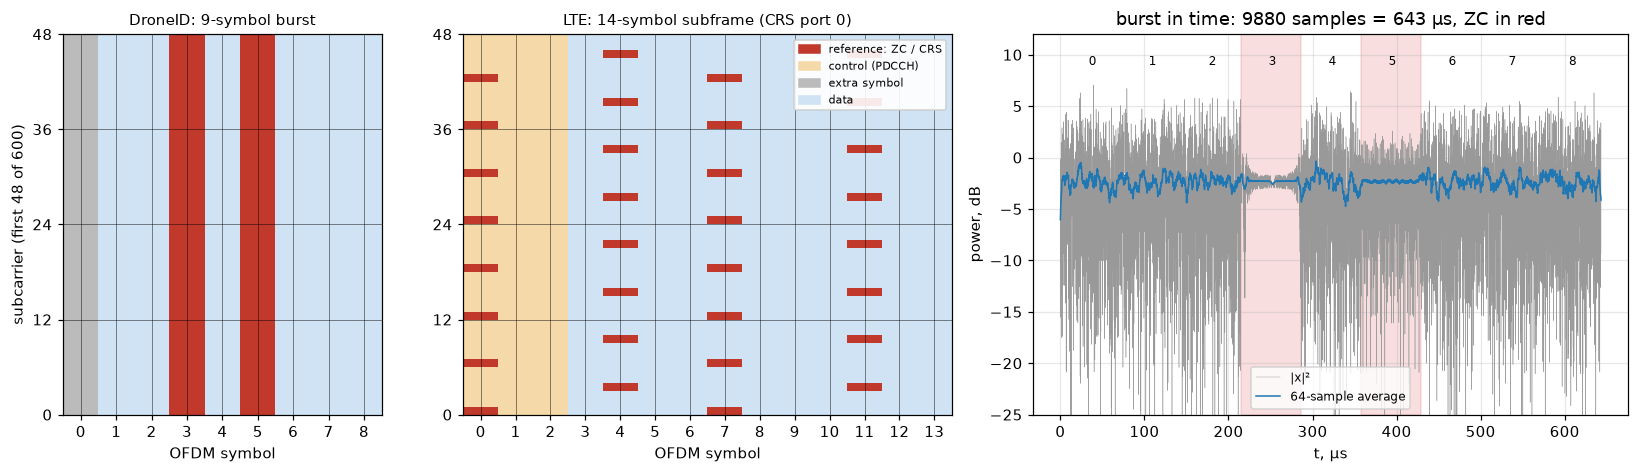

PAPR: data symbol 9.0 dB, ZC-600 2.7 dB, ZC-147 4.9 dB

                                   DroneID            LTE 10 MHz
duration, µs                           643                  1000
CP share                              6.7%                  6.7%
reference-RE share                   22.2%                  4.8%
info bits per burst/subframe          1384    CQI-driven: 1k–36k
bits per data RE                      0.38            0.15 … 5.5


In [3]:
_, _, Xb = drone_tx(1, rng)
fig, ax = plt.subplots(1, 3, figsize=(15, 4.4), gridspec_kw={"width_ratios": [0.75, 1.15, 1.4]})
cm = ListedColormap(["#cfe3f5", "#f5d9a8", "#c0392b", "#bbbbbb"])
G1 = np.zeros((N_SYM, 48)); G1[list(ZC_SYM)] = 2; G1[0] = 3
G2 = np.zeros((14, 48)); G2[:3] = 1
for s, sh in ((0, 0), (4, 3), (7, 0), (11, 3)):
    G2[s, sh::6] = 2
for a, M, t in ((ax[0], G1, "DroneID: 9-symbol burst"),
                (ax[1], G2, "LTE: 14-symbol subframe (CRS port 0)")):
    a.imshow(M.T, origin="lower", aspect="auto", cmap=cm, vmin=0, vmax=3, extent=[-0.5, M.shape[0] - 0.5, -0.5, 47.5])
    a.set_xticks(range(M.shape[0])); a.set_yticks(np.arange(0, 49, 12) - 0.5, [str(v) for v in range(0, 49, 12)])
    a.grid(True, color="k", lw=0.6, alpha=0.5); a.set_xlabel("OFDM symbol"); a.set_title(t, fontsize=10)
ax[0].set_ylabel("subcarrier (first 48 of 600)")
ax[1].legend(handles=[Patch(color=c, label=l) for c, l in [("#c0392b", "reference: ZC / CRS"),
             ("#f5d9a8", "control (PDCCH)"), ("#bbbbbb", "extra symbol"),
             ("#cfe3f5", "data")]], loc="upper right", fontsize=7, framealpha=0.9)
x = ofdm_mod(Xb)[0]; t = np.arange(len(x)) / FS * 1e6
ax[2].plot(t, 10 * np.log10(np.abs(x)**2 + 1e-6), lw=0.3, color="0.6", label="|x|²")
ax[2].plot(t, 10 * np.log10(np.convolve(np.abs(x)**2, np.ones(64) / 64, "same")), "C0", lw=1, label="64-sample average")
for s in ZC_SYM:
    ax[2].axvspan(SYM_OFF[s] / FS * 1e6, (SYM_OFF[s] + CP_B[s] + N_FFT) / FS * 1e6, color="C3", alpha=0.15)
for s in range(N_SYM):
    ax[2].text((SYM_OFF[s] + CP_B[s] + N_FFT / 2) / FS * 1e6, 9, str(s), ha="center", fontsize=8)
ax[2].set_ylim(-25, 12); ax[2].set_xlabel("t, µs"); ax[2].set_ylabel("power, dB"); ax[2].legend(fontsize=8, loc="lower center")
ax[2].set_title(f"burst in time: {len(x)} samples = {len(x)/FS*1e6:.0f} µs, ZC in red")
plt.tight_layout(); plt.show()

def papr_db(v):
    return 10 * np.log10(np.max(np.abs(v)**2) / np.mean(np.abs(v)**2))
sym = lambda s: x[SYM_OFF[s] + CP_B[s]: SYM_OFF[s] + CP_B[s] + N_FFT]
print(f"PAPR: data symbol {papr_db(sym(1)):.1f} dB, ZC-600 {papr_db(sym(3)):.1f} dB, ZC-147 {papr_db(sym(5)):.1f} dB")
lte_cp = (2 * 80 + 12 * 72) / (14 * N_FFT + 2 * 80 + 12 * 72)
print(f"\n{'':32}{'DroneID':>10}{'LTE 10 MHz':>22}")
for name, d, l in [("duration, µs", f"{L_BURST/FS*1e6:.0f}", "1000"),
                   ("CP share", f"{CP_B.sum()/L_BURST:.1%}", f"{lte_cp:.1%}"),
                   ("reference-RE share", f"{2/N_SYM:.1%}", f"{8/168:.1%}"),
                   ("info bits per burst/subframe", f"{N_INFO}", "CQI-driven: 1k–36k"),
                   ("bits per data RE", f"{N_INFO/(E_BITS/2):.2f}", "0.15 … 5.5")]:
    print(f"{name:32}{d:>10}{l:>22}")

## 2. Zadoff–Chu: CAZAC and the time–frequency link
$$z_u[n]=e^{-j\pi u\,n(n+1)/N_{zc}},\qquad N_{zc}=601\ (\text{prime}),\ n=0\dots600,$$
with the middle element dropped (it would land on DC). The properties that put ZC into the LTE PSS/PRACH/SRS and into this burst:
- **constant amplitude** on every subcarrier: the channel is probed uniformly, and the LS estimate $\hat H_k=Y_kz^*_k$ is equally accurate everywhere;
- **ideal cyclic autocorrelation**, and a cross-correlation of exactly $1/\sqrt{N_{zc}}$ between different roots.

The key point here is what a frequency offset does to a ZC. A shift by $q$ subcarriers gives
$$z_u[n-q]\,z_u^*[n]=e^{\,j\pi u(2qn-q^2+q)/N_{zc}}$$
— a linear phase in $n$, and a linear phase across frequency is a time shift of $(uq\bmod N_{zc})\cdot N_\text{FFT}/N_{zc}$ samples. A frequency offset is **indistinguishable** from a time shift.

- Root 600 ≡ −1 (mod 601): $z_{600}=z_1^*$, and $z_1$ is a discrete **chirp** (instantaneous frequency linear in $n$). It is the same chirp as in LoRa (`lora_sim`): a 1-subcarrier shift equals a −1.7-sample shift. The ambiguity function is a tilted ridge.
- Root 147: the same subcarrier moves the peak by 250 samples. The ridge is so steep that it wraps modulo 1024 and comes back into the ±40 window only at $\nu=\pm4$: $147\cdot4\bmod601=588\equiv-13$, i.e. $\tau=\mp22$ samples.
- A random QPSK symbol: a "thumbtack" at zero on a noise pedestal.

Two roots whose ridges have different slopes intersect only at the true point $(\tau,\nu)=(0,0)$. That is how one burst gives both the timing and the integer part of the frequency (section 3).

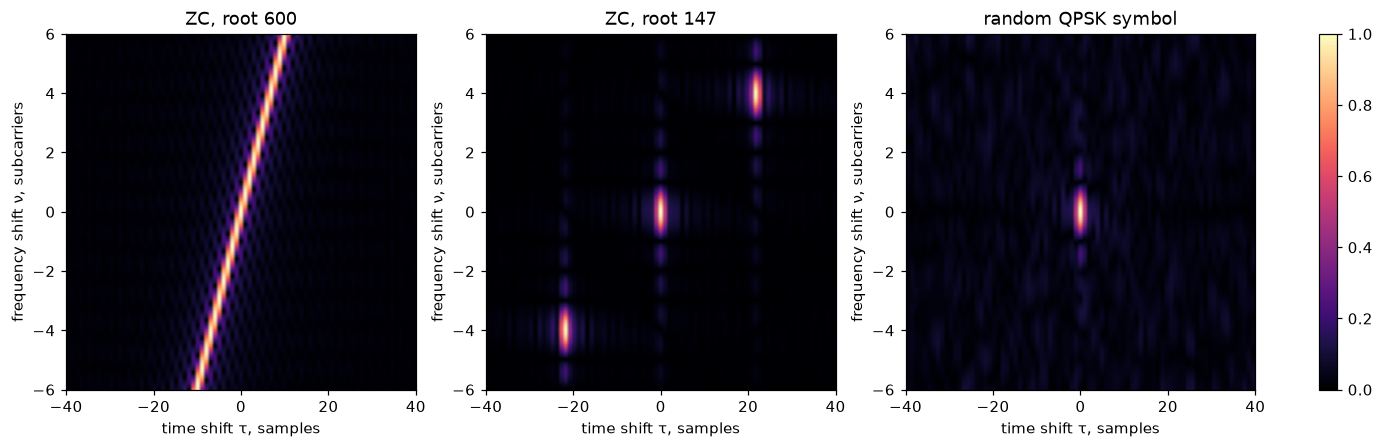

|ZC| on the subcarriers: min 1.000, max 1.000
Cyclic autocorrelation of ZC-600 outside the main lobe (|τ| ≥ 3): max -18.0 dB — just the sinc of a 600/1024 rectangular spectrum; a full ZC-601 on a 601-point grid would give exactly 0
Cross-correlation 600 × 147: max -23.8 dB; on a 601-point grid it would be exactly 1/√601 = -27.8 dB, interpolating to 1024 samples adds peaks between the grid points
A 1-subcarrier shift for root 600 ≡ a time shift of ((u·1) mod 601)·1024/601 = 1022.3 ≡ -1.7 samples
A 1-subcarrier shift for root 147 ≡ a time shift of ((u·1) mod 601)·1024/601 = 250.5 ≡ +250.5 samples


In [4]:
def tsym(vals, sc=SC_IDX):
    """one OFDM symbol without CP: values vals on subcarriers sc"""
    return ofdm_mod(vals[None, :], cp=np.array([0]), sc=sc)

def ambiguity(x, nus, lags):
    """|χ(τ, ν)| — normalized correlation of the symbol with itself shifted by τ samples and ν subcarriers"""
    n = np.arange(N_FFT); Xc = np.conj(np.fft.fft(x))
    return np.array([np.abs(np.fft.ifft(np.fft.fft(x * np.exp(2j * np.pi * nu * n / N_FFT)) * Xc))[lags % N_FFT]
                     for nu in nus]) / np.sum(np.abs(x)**2)

nus, lags = np.linspace(-6, 6, 241), np.arange(-40, 41)
syms = {"ZC, root 600": tsym(ZC_REF[3]), "ZC, root 147": tsym(ZC_REF[5]),
        "random QPSK symbol": tsym(qpsk(rng.integers(0, 2, 2 * N_SC)))}
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
for a, (k, v) in zip(ax, syms.items()):
    A = ambiguity(v, nus, lags)
    im = a.imshow(A, origin="lower", aspect="auto", extent=[lags[0], lags[-1], nus[0], nus[-1]], cmap="magma", vmin=0, vmax=1)
    a.set_xlabel("time shift τ, samples"); a.set_ylabel("frequency shift ν, subcarriers"); a.set_title(k)
    a.grid(False)
plt.colorbar(im, ax=ax, fraction=0.02); plt.show()

z6, z1 = ZC_REF[3], ZC_REF[5]
ac = np.abs(np.fft.ifft(np.abs(np.fft.fft(tsym(z6)))**2)) / N_SC
side = np.r_[ac[3:N_FFT - 2]].max()
print(f"|ZC| on the subcarriers: min {np.abs(z6).min():.3f}, max {np.abs(z6).max():.3f}")
print(f"Cyclic autocorrelation of ZC-600 outside the main lobe (|τ| ≥ 3): max {20*np.log10(side):.1f} dB — just the sinc of a 600/1024 rectangular spectrum; a full ZC-601 on a 601-point grid would give exactly 0")
xc = np.abs(np.fft.ifft(np.fft.fft(tsym(z6)) * np.conj(np.fft.fft(tsym(z1))))) / N_SC
print(f"Cross-correlation 600 × 147: max {20*np.log10(xc.max()):.1f} dB; on a 601-point grid it would be exactly 1/√601 = {20*np.log10(1/np.sqrt(601)):.1f} dB, interpolating to 1024 samples adds peaks between the grid points")
for u in (600, 147):
    print(f"A 1-subcarrier shift for root {u} ≡ a time shift of ((u·1) mod 601)·1024/601 = {((u * 1) % 601) * 1024 / 601:.1f} ≡ {(((u % 601) * 1024 / 601 + 512) % 1024) - 512:+.1f} samples")

### Detection: ZC-600 vs the LTE PSS
Correlation detector: $T=\max_{\tau<W}|c(\tau)|^2/(N_0N_{sc})$, $c(\tau)=\sum_n r[n+\tau]\,s^*[n]$. Without a signal $T$ is exponential at every lag, hence the threshold $\eta=-\ln\!\big(1-(1-P_\text{FA})^{1/W}\big)$. With a signal, at the right lag $2T\sim\chi'^2_2(2N_{sc}\,\text{SNR})$, so
$$P_D=Q_1\!\big(\sqrt{2N_{sc}\text{SNR}},\ \sqrt{2\eta}\big).$$
At equal per-subcarrier SNR, 600 subcarriers carry $10\log_{10}(600/62)=9.9$ dB more energy than the PSS. If instead all of the transmitter's power goes into 62 subcarriers, the energies are equal and the advantage disappears. The wideband ZC then wins elsewhere: timing resolution $\sim1/9$ MHz ≈ 110 ns instead of ~1 µs, and frequency diversity in multipath. In LTE the PSS shares the base station's power with the whole carrier, so the per-subcarrier comparison is the fair one.

DroneID ZC-600 (600 sc)   : false alarms 0.0010 (target 0.001); P_D = 0.9 at SNR ≈ -15.1 dB


LTE PSS (62 sc)           : false alarms 0.0007 (target 0.001); P_D = 0.9 at SNR ≈ -5.3 dB


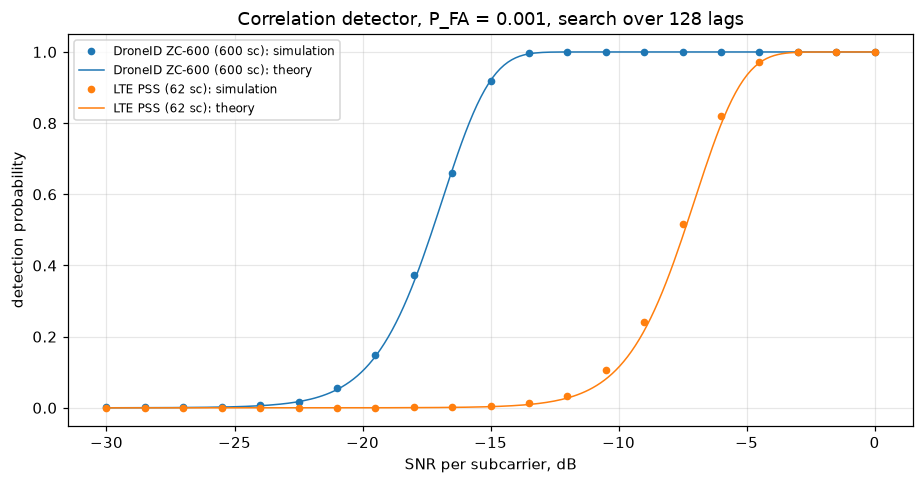

Gap = 10·log10(600/62) = 9.9 dB: the reference-symbol energy scales with the number of subcarriers


In [5]:
# Detection: DroneID ZC-600 vs LTE PSS (ZC-63, root 25, 62 subcarriers) at equal per-subcarrier SNR
n63 = np.arange(63)
PSS = np.delete(np.exp(-1j * np.pi * 25 * n63 * (n63 + 1) / 63), 31)
SC_PSS = np.r_[-31:0, 1:32]
refs = {"DroneID ZC-600 (600 sc)": (tsym(ZC_REF[3]), N_SC), "LTE PSS (62 sc)": (tsym(PSS, SC_PSS), 62)}
W, PFA, T = 128, 1e-3, 3000                       # timing search window, false-alarm rate, trials
eta = -np.log(1 - (1 - PFA) ** (1 / W))           # threshold on |c|²/(N0·Nsc): max of W exponentials

def detect(s, nsc, snr_db, present):
    n0 = 10 ** (-snr_db / 10)
    tau = rng.integers(0, W, T)
    r = np.sqrt(n0) * crandn((T, N_FFT), rng)
    if present:
        r += np.stack([np.roll(s, k) for k in tau])
    c = np.fft.ifft(np.fft.fft(r, axis=1) * np.conj(np.fft.fft(s)), axis=1)[:, :W]
    return (np.abs(c)**2 / (n0 * nsc)).max(1) > eta

snrs = np.arange(-30, 1, 1.5)
fig, a = plt.subplots(figsize=(8.5, 4.5))
for i, (k, (s, nsc)) in enumerate(refs.items()):
    pd = [detect(s, nsc, v, True).mean() for v in snrs]
    a.plot(snrs, pd, f"C{i}o", ms=4, label=f"{k}: simulation")
    sg = np.linspace(snrs[0], snrs[-1], 200)
    a.plot(sg, ncx2.sf(2 * eta, 2, 2 * nsc * 10 ** (sg / 10)), f"C{i}-", lw=1, label=f"{k}: theory")
    print(f"{k:26}: false alarms {detect(s, nsc, 0, False).mean():.4f} (target {PFA}); "
          f"P_D = 0.9 at SNR ≈ {sg[np.argmax(ncx2.sf(2*eta, 2, 2*nsc*10**(sg/10)) > 0.9)]:.1f} dB")
a.set_xlabel("SNR per subcarrier, dB"); a.set_ylabel("detection probability"); a.legend(fontsize=8)
a.set_title(f"Correlation detector, P_FA = {PFA}, search over {W} lags")
plt.tight_layout(); plt.show()
print(f"Gap = 10·log10(600/62) = {10*np.log10(600/62):.1f} dB: the reference-symbol energy scales with the number of subcarriers")

## 3. Synchronizing from scratch: timing, fractional and integer frequency offset
In LTE the phone locks its oscillator to the base station (accurate to ±0.05 ppm) and afterwards only tracks a small residual. The drone and the controller have two cheap 10–20 ppm crystals: at 2.44 GHz that is tens of kilohertz, i.e. several subcarriers, plus Doppler (20 m/s at 5.8 GHz is 390 Hz). And this happens for every burst. The receiver (as in `proto17` and the NDSS paper) works in three steps:

**1. CP → timing and fractional offset.** An offset $\varepsilon$ (in subcarriers) rotates the CP copy relative to the symbol tail by $e^{j2\pi\varepsilon}$:
$$\Gamma(\theta)=\sum_s\sum_{n<N_{cp,s}}r^*[\theta+o_s+n]\,r[\theta+o_s+n+N],\qquad\hat\theta=\arg\max\frac{|\Gamma|}{E},\quad\hat\varepsilon=\frac{\angle\Gamma(\hat\theta)}{2\pi}\in\pm\tfrac12 .$$
The sum runs over all $L_{cp}=664$ CP samples. With per-sample SNR $\rho=\text{SNR}\cdot600/1024$
$$\sigma_\varepsilon\approx\frac1{2\pi}\sqrt{\frac{1/\rho+1/(2\rho^2)}{L_{cp}}}.$$

**2. ZC → integer offset $q$.** For each hypothesis $q$ the receiver estimates the impulse response $h_q=\text{IFFT}\big(Y[k+q]\,z^*[k]\big)$ and looks for its peak within ±24 samples of the detected start. From section 2, ZC-600 gives the same peak for neighbouring hypotheses, shifted by just 1.7 samples. Only the loss of $|q|$ edge subcarriers tells them apart, so this root alone makes errors even at high SNR. ZC-147 throws wrong hypotheses outside the window, except for an offset of exactly 4 subcarriers (a peak at ∓22 samples, inside the ±24 window): hence its ~5 % errors. The two roots' ridges intersect only at the true point, and the product of $|h_q|$ over both symbols is unambiguous.

**3. Phase between the ZCs → fine offset.** Symbols 3 and 5 are $2(N+N_{cp})$ samples apart: $\varphi=\tfrac12\angle\sum_kH_{5,k}H^*_{3,k}$. The error is averaged over 600 subcarriers and the baseline is 2.1× longer than the CP's, so it is ~10 dB more accurate. But it is unambiguous only within ±3.5 kHz, which is why the CP comes first.

At low SNR the CP errors exceed the formula: this is the threshold effect, where the phase occasionally jumps. The formula is a high-SNR asymptote.

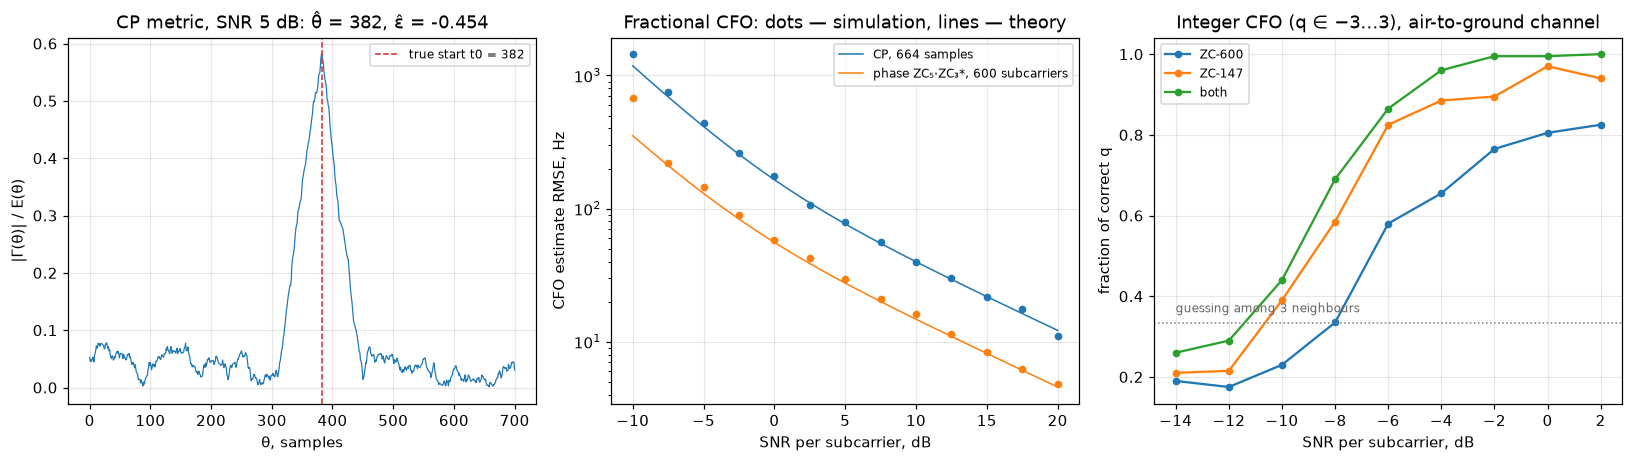

SNR -10.0 dB: CFO RMSE from CP  1446.3 Hz, from ZC  677.3 Hz (theory  1181.7 /  352.7)
SNR   0.0 dB: CFO RMSE from CP   177.1 Hz, from ZC   58.0 Hz (theory   164.8 /   55.8)
SNR  10.0 dB: CFO RMSE from CP    39.8 Hz, from ZC   16.2 Hz (theory    39.9 /   14.8)
SNR  20.0 dB: CFO RMSE from CP    11.0 Hz, from ZC    4.8 Hz (theory    12.2 /    4.6)
Unambiguous range: CP ±7.5 kHz, phase between ZC symbols (2 symbols apart) ±3.5 kHz, integer ZC search ±60 kHz (Q = 4); a 20 ppm crystal at 2.44 GHz is off by up to 49 kHz


In [6]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.3))
_, _, X = drone_tx(1, rng)
y, t0 = air(X, "a2g", SNR_DB, rng)
th, eps, M = cp_sync(y)
ax[0].plot(np.arange(M.shape[-1]), M[0], lw=0.8)
ax[0].axvline(t0[0], color="C3", ls="--", lw=1, label=f"true start t0 = {t0[0]}")
ax[0].set_xlabel("θ, samples"); ax[0].set_ylabel("|Γ(θ)| / E(θ)"); ax[0].legend(fontsize=8)
ax[0].set_title(f"CP metric, SNR {SNR_DB} dB: θ̂ = {th[0]}, ε̂ = {eps[0]:+.3f}")

# fractional CFO accuracy: CP vs phase between the ZC symbols (AWGN, known start)
snrs = np.arange(-10, 21, 2.5); B = 400
r_cp, r_zc = [], []
for v in snrs:
    _, _, X = drone_tx(B, rng)
    eps_t = rng.uniform(-0.2, 0.2, B)
    y, t0 = air(X, "awgn", v, rng, cfo_hz=eps_t * DF)
    _, _, M = cp_sync(y)
    p = np.conj(y[:, :-N_FFT]) * y[:, N_FFT:]
    G = sum(p[np.arange(B)[:, None], t0[:, None] + o + np.arange(c)].sum(1) for o, c in zip(SYM_OFF, CP_B))
    r_cp.append(np.sqrt(np.mean((np.angle(G) / (2 * np.pi) - eps_t)**2)))
    _, phi, _, _ = zc_channel(ofdm_demod(y, t0), keep=None)
    r_zc.append(np.sqrt(np.mean((phi * N_FFT / (2 * np.pi * (N_FFT + 72)) - eps_t)**2)))
sg = np.linspace(snrs[0], snrs[-1], 200); g = 10 ** (sg / 10); rho = g * N_SC / N_FFT; n0 = 1 / g
th_cp = np.sqrt((1 / rho + 1 / (2 * rho**2)) / CP_B.sum()) / (2 * np.pi)
th_zc = np.sqrt((2 * n0 + n0**2) / (2 * N_SC)) / (2 * np.pi * 2 * (N_FFT + 72) / N_FFT)
for i, (r, th_, lab) in enumerate([(r_cp, th_cp, "CP, 664 samples"), (r_zc, th_zc, "phase ZC₅·ZC₃*, 600 subcarriers")]):
    ax[1].semilogy(snrs, np.array(r) * DF, f"C{i}o", ms=4)
    ax[1].semilogy(sg, th_ * DF, f"C{i}-", lw=1, label=lab)
ax[1].set_xlabel("SNR per subcarrier, dB"); ax[1].set_ylabel("CFO estimate RMSE, Hz")
ax[1].legend(fontsize=8); ax[1].set_title("Fractional CFO: dots — simulation, lines — theory")

# integer CFO: one ZC vs two
snrs2 = np.arange(-14, 3, 2); B = 200
res = {k: [] for k in ("ZC-600", "ZC-147", "both")}
for v in snrs2:
    _, _, X = drone_tx(B, rng)
    qt = rng.integers(-3, 4, B)
    y, t0 = air(X, "a2g", v, rng, cfo_hz=(qt + rng.uniform(-0.4, 0.4, B)) * DF)
    th, eps, _ = cp_sync(y)
    y = y * np.exp(-2j * np.pi * eps[:, None] * np.arange(y.shape[1]) / N_FFT)
    Yf = ofdm_demod(y, np.maximum(th - 6, 0), full=True)
    for k, s in zip(res, ((3,), (5,), (3, 5))):
        res[k].append(np.mean(int_cfo(Yf, s)[0] == qt))
for i, (k, r) in enumerate(res.items()):
    ax[2].plot(snrs2, r, f"C{i}o-", ms=4, label=k)
ax[2].axhline(1 / 3, color="0.5", ls=":", lw=1)
ax[2].text(snrs2[0], 0.36, "guessing among 3 neighbours", fontsize=8, color="0.4")
ax[2].set_xlabel("SNR per subcarrier, dB"); ax[2].set_ylabel("fraction of correct q"); ax[2].legend(fontsize=8)
ax[2].set_title("Integer CFO (q ∈ −3…3), air-to-ground channel")
plt.tight_layout(); plt.show()
for v, a, b in zip(snrs, r_cp, r_zc):
    if v in (-10, 0, 10, 20):
        print(f"SNR {v:5.1f} dB: CFO RMSE from CP {a*DF:7.1f} Hz, from ZC {b*DF:6.1f} Hz "
              f"(theory {np.interp(v, sg, th_cp)*DF:7.1f} / {np.interp(v, sg, th_zc)*DF:6.1f})")
print(f"Unambiguous range: CP ±{DF/2/1e3:.1f} kHz, phase between ZC symbols (2 symbols apart) ±{DF*N_FFT/(4*(N_FFT+72))/1e3:.1f} kHz, "
      f"integer ZC search ±{4*DF/1e3:.0f} kHz (Q = 4); a 20 ppm crystal at {FC_GHZ} GHz is off by up to {20e-6*FC_GHZ*1e9/1e3:.0f} kHz")

## 4. The air-to-ground channel: line of sight instead of multipath
The LTE models (EPA/EVA/ETU) are Rayleigh: no line of sight, many scatterers, $\tau_\text{rms}$ of hundreds of nanoseconds. A drone at 100+ m sees the controller directly. The signal is a direct ray, a ground reflection and weak diffuse scatter, i.e. a **Rician** channel with $K=P_\text{LoS}/P_\text{diff}$. The direct and reflected rays are $\Delta\tau=2h_th_r/(cd)$ apart, about 1 ns at 1 km and well within one sample. Together they therefore act as a single specular component whose amplitude depends on range (section 7).

For QPSK with $L$-antenna MRC, Craig's formula uses the moment-generating function (MGF) of the SNR:
$$P_b=\frac1\pi\int_0^{\pi/2}M_\gamma\!\Big(-\frac{1}{2\sin^2\theta}\Big)^{L}d\theta,\qquad M_\gamma(s)=\frac{1+K}{1+K-s\bar\gamma}\exp\frac{Ks\bar\gamma}{1+K-s\bar\gamma}.$$
$K=0$ is Rayleigh ($P_b\propto1/\bar\gamma$), $K\to\infty$ is AWGN.

The left panel shows how air-to-ground differs from EVA: $|H(f)|$ is almost flat across all 9 MHz ($B_c\approx10$ MHz vs 0.56). That cuts both ways: there are no deep nulls on individual subcarriers, but when the burst fades it fades **as a whole**, and the frequency diversity LTE relies on is gone. The gain has to come from $K$ (keeping line of sight) and from antennas: in O3 the controller has 4 receivers. On the right: with 4-antenna MRC even Rayleigh beats a single antenna in AWGN: the 6 dB array gain outweighs the fading margin.

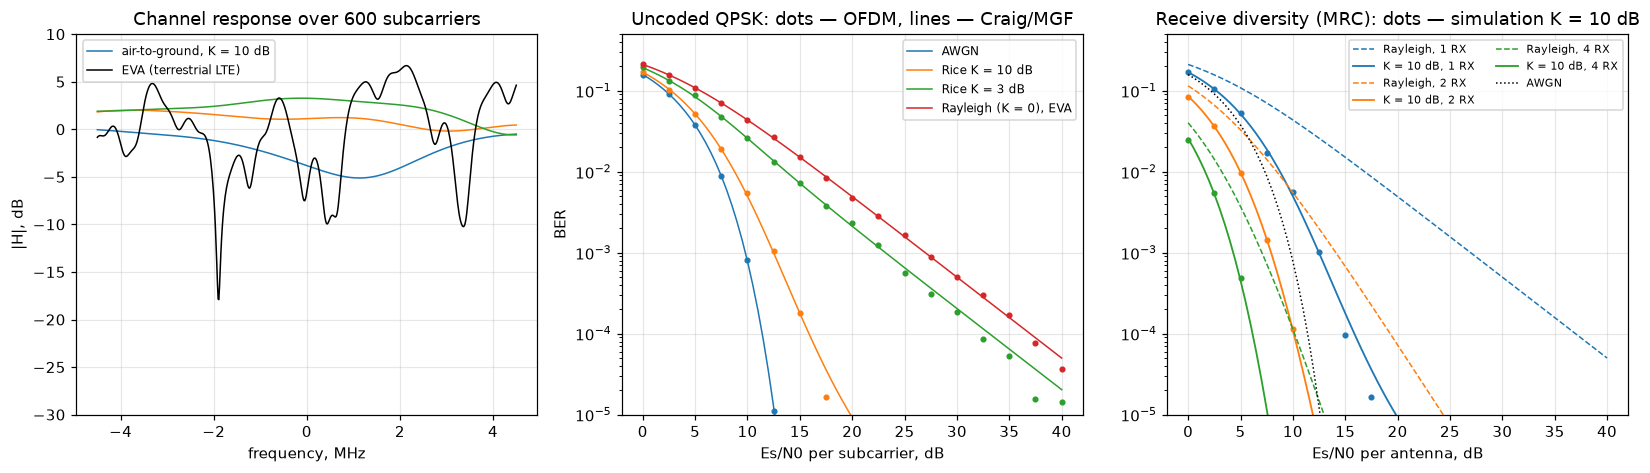

a2g : τ_rms =    21 ns, B_c ≈ 1/(5τ_rms) =  9.61 MHz
eva : τ_rms =   357 ns, B_c ≈ 1/(5τ_rms) =  0.56 MHz
BER 1e-3, Rice K = 10 dB          : fading margin  +2.5 dB vs AWGN; with 4-antenna MRC  -5.5 dB (SNR per antenna)
BER 1e-3, Rice K = 3 dB           : fading margin +13.5 dB vs AWGN; with 4-antenna MRC  -4.0 dB (SNR per antenna)
BER 1e-3, Rayleigh (K = 0), EVA   : fading margin +17.0 dB vs AWGN; with 4-antenna MRC  -2.5 dB (SNR per antenna)


In [7]:
def ber_qpsk(snr_db, K_db=None, L=1):
    """QPSK, coherent, L-branch MRC. Craig's formula: Pb = (1/π)∫₀^{π/2} M_γ(−1/(2 sin²θ))^L dθ,
    M_γ(s) = (1+K)/(1+K−sγ̄)·exp(Ksγ̄/(1+K−sγ̄)) is the MGF of a Rician SNR. K_db=None — AWGN, K = 0 (−inf dB) — Rayleigh."""
    g = 10 ** (np.asarray(snr_db, float) / 10)
    if K_db is None:
        return 0.5 * erfc(np.sqrt(L * g / 2))
    K = 10 ** (K_db / 10)
    def pb(gb):
        mgf = lambda s: (1 + K) / (1 + K - s * gb) * np.exp(K * s * gb / (1 + K - s * gb))
        return quad(lambda t: mgf(-1 / (2 * np.sin(t)**2)) ** L, 0, np.pi / 2)[0] / np.pi
    return np.array([pb(v) for v in np.atleast_1d(g)])

def tau_rms_taps(kind, K_db=K_RICE_DB):
    if kind == "eva":
        t = EVA[0]; p = 10 ** (np.array(EVA[1]) / 10)
    else:
        K = 10 ** (K_db / 10); t = np.arange(6) / FS
        p = np.exp(-np.arange(6.0)); p = p / p.sum() / (K + 1); p[0] += K / (K + 1)
    p = p / p.sum()
    return np.sqrt((p * t**2).sum() - (p * t).sum()**2)

fig, ax = plt.subplots(1, 3, figsize=(15, 4.4))
f_sc = SC_IDX * DF / 1e6
for i in range(3):
    g, d = taps("a2g", np.random.default_rng(20 + i))
    ax[0].plot(f_sc, 20 * np.log10(np.abs(freq_resp(g, d))), f"C{i}", lw=1, label=f"air-to-ground, K = {K_RICE_DB} dB" if i == 0 else None)
g, d = taps("eva", np.random.default_rng(5))
ax[0].plot(f_sc, 20 * np.log10(np.abs(freq_resp(g, d))), "k", lw=1, label="EVA (terrestrial LTE)")
ax[0].set_ylim(-30, 10); ax[0].set_xlabel("frequency, MHz"); ax[0].set_ylabel("|H|, dB"); ax[0].legend(fontsize=8)
ax[0].set_title("Channel response over 600 subcarriers")

snrs = np.arange(0, 41, 2.5); sg = np.linspace(0, 40, 81)
def sim_ber(kind, snr_db, L=1, B=1500, K_db=K_RICE_DB):
    """flat per-subcarrier channel (H_k from taps), MRC over L independent antennas"""
    b = rng.integers(0, 2, (B, 2 * N_SC)); s = qpsk(b); n0 = 10 ** (-snr_db / 10)
    num = den = 0
    for _ in range(L):
        g, d = taps(kind, rng, (B,), K_db=K_db)
        H = freq_resp(g, d); y = H * s + np.sqrt(n0) * crandn(s.shape, rng)
        num = num + np.conj(H) * y; den = den + np.abs(H)**2
    return np.mean((qpsk_llr(num / den, 1.0) < 0) != b)
curves = [(None, "awgn", "AWGN"), (K_RICE_DB, "a2g", f"Rice K = {K_RICE_DB} dB"), (3, "a2g", "Rice K = 3 dB"),
          (-np.inf, "eva", "Rayleigh (K = 0), EVA")]
for i, (K, kind, lab) in enumerate(curves):
    ax[1].semilogy(sg, ber_qpsk(sg, K), f"C{i}-", lw=1, label=lab)
    meas = [sim_ber(kind, v, K_db=K if K is not None else 0) for v in snrs]
    ax[1].semilogy(snrs, np.maximum(meas, 1e-9), f"C{i}o", ms=3)
ax[1].set_ylim(1e-5, 0.5); ax[1].set_xlabel("Es/N0 per subcarrier, dB"); ax[1].set_ylabel("BER"); ax[1].legend(fontsize=8)
ax[1].set_title("Uncoded QPSK: dots — OFDM, lines — Craig/MGF")
for j, L in enumerate((1, 2, 4)):
    ax[2].semilogy(sg, ber_qpsk(sg, -np.inf, L), f"C{j}--", lw=1, label=f"Rayleigh, {L} RX")
    ax[2].semilogy(sg, ber_qpsk(sg, K_RICE_DB, L), f"C{j}-", lw=1.2, label=f"K = {K_RICE_DB} dB, {L} RX")
    ax[2].semilogy(snrs, np.maximum([sim_ber("a2g", v, L, B=600) for v in snrs], 1e-9), f"C{j}o", ms=3)
ax[2].semilogy(sg, ber_qpsk(sg), "k:", lw=1, label="AWGN")
ax[2].set_ylim(1e-5, 0.5); ax[2].set_xlabel("Es/N0 per antenna, dB"); ax[2].legend(fontsize=7, ncol=2)
ax[2].set_title("Receive diversity (MRC): dots — simulation K = 10 dB")
plt.tight_layout(); plt.show()

for k in ("a2g", "eva"):
    tr = tau_rms_taps(k)
    print(f"{k:4}: τ_rms = {tr*1e9:5.0f} ns, B_c ≈ 1/(5τ_rms) = {1/(5*tr)/1e6:5.2f} MHz")
thr = lambda f: sg[np.argmax(f < 1e-3)]
base = thr(ber_qpsk(sg))
for K, _, lab in curves[1:]:
    print(f"BER 1e-3, {lab:24}: fading margin {thr(ber_qpsk(sg, K)) - base:+5.1f} dB vs AWGN; with 4-antenna MRC "
          f"{thr(ber_qpsk(sg, K, 4)) - base:+5.1f} dB (SNR per antenna)")

## 5. Channel estimation without pilots in the data
There are no CRS in the burst: the channel comes from the two ZC symbols. The LS estimate $\hat H_k=Y_kz_k^*$ exists on **every one** of the 600 subcarriers, so no frequency interpolation is needed, unlike the LTE CRS (every 6th subcarrier). In time, a residual offset $\delta f$ adds a phase of $\varphi=2\pi\,\delta f\,(N+N_{cp})/f_s$ per symbol between the ZC symbols. If $H$ is taken from symbol 3 alone, the constellation rotates more the farther the symbol is from it (the "walking phase" in `proto17`). The model $\hat H_s=\bar H\,e^{j\varphi(s-4)}$ from both ZC symbols removes this.

Estimation noise: each LS estimate has error variance $N_0$, the mean of two has $N_0/2$, so after equalization the effective noise is ≈ $1.5N_0$ (the dashed line on the EVM plot). At SNR ≈ 0 dB, where this code operates, that is a lot: dividing by a noisy $\hat H$ wrecks the LLRs. What helps is that the ZC fills the **whole** band. The impulse response is short (≤ CP = 72 samples ≈ 42 taps of a 600-point IFFT), while the noise is spread over all 600 taps. An IFFT, a 52-tap window and an FFT back cut the noise by $600/52$ (−10.6 dB). Sparse CRS do not allow this, because they need interpolation first.

The window has a floor. 600 subcarriers out of 1024 are not a period, so the phase "breaks" at the band edges: leakage leaves an error of ~−20 dB at any SNR. At high SNR raw LS is better. Real receivers use MMSE or soft windows; at SNR ≈ 0 dB this simple version is enough.

The price is 22 % of the resources spent on reference symbols vs 4.8 % in LTE: a long stream is best estimated from sparse pilots, an isolated burst from dense ones.

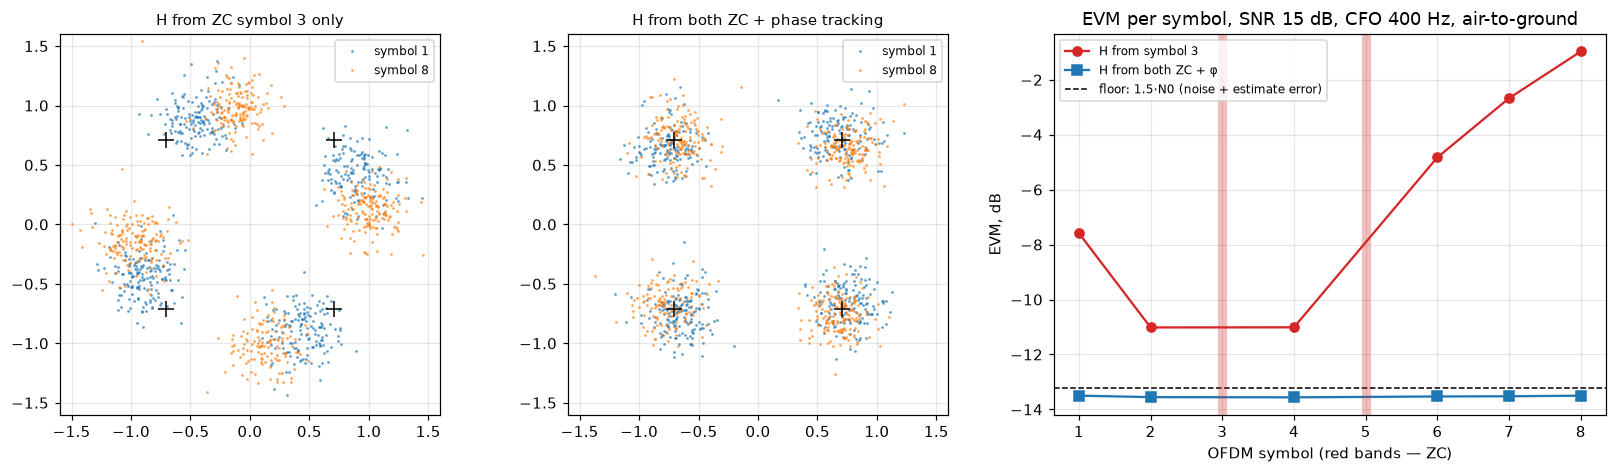

Phase advance per symbol: estimated 10.31°, theory 360°·400·(1024+72)/f_s = 10.28°

MSE of the ZC-based H estimate (CFO corrected, air-to-ground and EVA):


  a2g  SNR  -5 dB: LS    2.1 (theory N0/2    2.0), LS + DFT window   -8.1 (theory N0/2·52/600   -8.6) dB


  a2g  SNR   0 dB: LS   -3.0 (theory N0/2   -3.0), LS + DFT window  -12.6 (theory N0/2·52/600  -13.6) dB


  a2g  SNR  10 dB: LS  -13.0 (theory N0/2  -13.0), LS + DFT window  -18.8 (theory N0/2·52/600  -23.6) dB


  a2g  SNR  20 dB: LS  -23.0 (theory N0/2  -23.0), LS + DFT window  -20.2 (theory N0/2·52/600  -33.6) dB


  eva  SNR  -5 dB: LS    2.1 (theory N0/2    2.0), LS + DFT window   -8.2 (theory N0/2·52/600   -8.6) dB


  eva  SNR   0 dB: LS   -2.9 (theory N0/2   -3.0), LS + DFT window  -12.8 (theory N0/2·52/600  -13.6) dB


  eva  SNR  10 dB: LS  -13.0 (theory N0/2  -13.0), LS + DFT window  -19.7 (theory N0/2·52/600  -23.6) dB


  eva  SNR  20 dB: LS  -23.0 (theory N0/2  -23.0), LS + DFT window  -21.7 (theory N0/2·52/600  -33.6) dB


In [8]:
snr5 = SNR_DB + 10
_, e5, X = drone_tx(300, rng)
y, t0 = air(X, "a2g", snr5, rng, cfo_hz=400.0)          # residual CFO of 400 Hz left uncorrected
Y = ofdm_demod(y, t0)
Hs, phi, n0e, H3 = zc_channel(Y)
Xd = X[:, DATA_SYM]
Z_hold = Y[:, DATA_SYM] / H3[:, None, :]                  # H from symbol 3 for all
Z_trk = Y[:, DATA_SYM] / Hs                               # H from both ZC + phase drift
fig, ax = plt.subplots(1, 3, figsize=(15, 4.4), gridspec_kw={"width_ratios": [1, 1, 1.3]})
for a, Z, t in ((ax[0], Z_hold, "H from ZC symbol 3 only"), (ax[1], Z_trk, "H from both ZC + phase tracking")):
    for j, s in ((0, 1), (5, 8)):
        a.plot(Z[0, j].real, Z[0, j].imag, ".", ms=2, alpha=0.5, label=f"symbol {s}")
    a.plot([-0.71, 0.71, -0.71, 0.71], [-0.71, -0.71, 0.71, 0.71], "k+", ms=10)
    a.set_aspect("equal"); a.set_xlim(-1.6, 1.6); a.set_ylim(-1.6, 1.6); a.legend(fontsize=8, loc="upper right"); a.set_title(t, fontsize=10)
evm = lambda Z: 10 * np.log10(np.mean(np.abs(Z - Xd)**2, axis=(0, 2)))
ax[2].plot(DATA_SYM, evm(Z_hold), "C3o-", label="H from symbol 3")
ax[2].plot(DATA_SYM, evm(Z_trk), "C0s-", label="H from both ZC + φ")
ax[2].axhline(10 * np.log10(1.5 * 10 ** (-snr5 / 10)), color="k", ls="--", lw=1, label="floor: 1.5·N0 (noise + estimate error)")
for s in ZC_SYM:
    ax[2].axvline(s, color="C3", alpha=0.3, lw=6)
ax[2].set_xlabel("OFDM symbol (red bands — ZC)"); ax[2].set_ylabel("EVM, dB"); ax[2].legend(fontsize=8)
ax[2].set_title(f"EVM per symbol, SNR {snr5} dB, CFO 400 Hz, air-to-ground")
plt.tight_layout(); plt.show()
print(f"Phase advance per symbol: estimated {np.degrees(np.median(phi)):.2f}°, theory 360°·400·(1024+72)/f_s = {360*400*(N_FFT+72)/FS:.2f}°")

print("\nMSE of the ZC-based H estimate (CFO corrected, air-to-ground and EVA):")
for kind in ("a2g", "eva"):
    for v in (-5, 0, 10, 20):
        _, _, X = drone_tx(200, rng)
        y, t0, H = air(X, kind, v, rng, cfo_hz=0.0, ret_h=True)
        Y = ofdm_demod(y, t0 - 6)
        H = H * np.exp(-2j * np.pi * SC_IDX * 6 / N_FFT)                # FFT window 6 samples early, as in the receiver
        m = [10 * np.log10(np.mean(np.abs(zc_channel(Y, k)[0] - H[:, None, :])**2)) for k in (None, KEEP)]
        n0 = 10 ** (-v / 10)
        print(f"  {kind:4} SNR {v:3d} dB: LS {m[0]:6.1f} (theory N0/2 {10*np.log10(n0/2):6.1f}), "
              f"LS + DFT window {m[1]:6.1f} (theory N0/2·{sum(KEEP)}/{N_SC} {10*np.log10(n0/2*sum(KEEP)/N_SC):6.1f}) dB")


## 6. The code: the LTE turbo code, the circular buffer and repeats
The chain (36.212, recovered from the firmware): 1384 bits + CRC24A → $K=1408$ → LTE turbo code $R=1/3$ (details in `turbo_sim`) → three streams of $K+4=1412$ bits → **sub-block interleaver** (32 columns, the standard's column permutation) → **circular buffer** $w=[v_0,\ v_1/v_2\text{ interlaced}]$ → read $E=7200$ bits from position $k_0=2R_\text{sb}$, wrapping around.

4236 bits are not enough for 7200, so the buffer is traversed 1.7 times: 94 % of the systematic and 58 % of the parity bits are sent **twice**. The left panel shows how the buffer is read: first the systematic bits (shuffled by the sub-block interleaver), then both parities interlaced, then the second lap. The receiver simply adds the LLRs of the repeats. This is chase combining within one burst, worth $10\log_{10}(7200/4236)=2.3$ dB of energy. The result: $R=0.192$, 0.384 bits per subcarrier, a Shannon limit for QPSK of −5.1 dB. The LTE PBCH works the same way: a broadcast that must be heard far away is coded with a large margin and with repeats.

Curves on the right (a burst counts as received when its CRC passes):
- **ideal reception** — LLRs straight from AWGN, no OFDM and no synchronization: ~1.7 dB from Shannon, as expected for a turbo code at $K\approx1400$;
- **full receiver, AWGN** — everything from sections 3 and 5 (unknown start, 23 kHz offset, ZC-based estimation): ~0.5 dB loss;
- **air-to-ground** — a shallow curve: the whole burst fades together (section 4), and the code cannot "borrow" energy from good subcarriers. Only $K$ makes it steeper: at 10 dB the fades are shallow, ~2.4 dB per decade;
- **EVA** — 1.5–2 dB to the right, but with almost the same slope. Of EVA's 9 paths, about four are strong and independent on the 65 ns grid, so the frequency diversity (section 8 of `lte_sim`) is of order 4. Line of sight with $K=10$ dB gives a comparable "effective" steepness without any diversity. Lose the line of sight (`K_RICE_DB = 0`) and the flat channel falls many dB behind EVA.

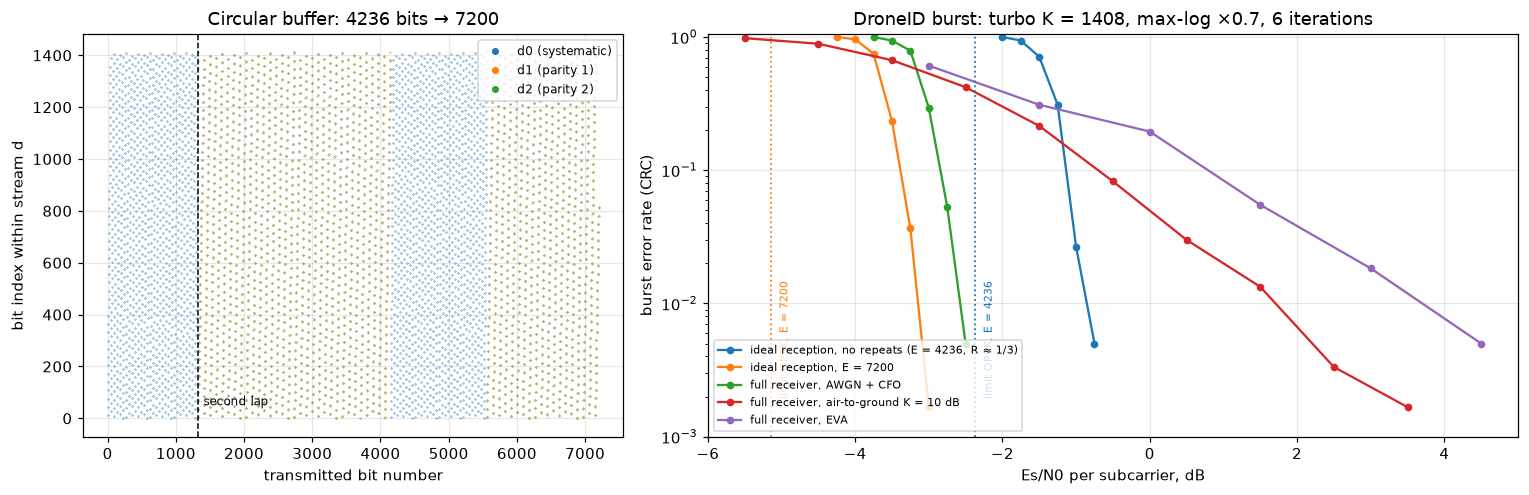

d0: sent once 6%, twice 94%
d1: sent once 42%, twice 58%
d2: sent once 42%, twice 58%
Shannon limit for QPSK: -5.14 dB (E = 7200), -2.37 dB (E = 4236)
                                                               BLER 10 %  BLER 1 %
ideal reception, no repeats (E = 4236, R ≈ 1/3)                  -1.13 dB  -0.85 dB
ideal reception, E = 7200                                        -3.39 dB  -3.14 dB
full receiver, AWGN + CFO                                        -2.84 dB  -2.57 dB
full receiver, air-to-ground K = 10 dB                           -0.70 dB   1.71 dB
full receiver, EVA                                                0.79 dB   3.70 dB
Repeats buy 2.3 dB (just the energy: 10·log10(7200/4236) = 2.3 dB); the real receiver loses 0.5 dB


In [9]:
def biawgn_cap(g):
    """BPSK-AWGN capacity, bits, at SNR g per dimension (signal / noise variance)"""
    mu = 2 * g
    f = lambda l: np.log2(1 + np.exp(-l)) * np.exp(-(l - mu)**2 / (4 * mu)) / np.sqrt(4 * np.pi * mu)
    return 1 - quad(f, mu - 40 * np.sqrt(mu), mu + 40 * np.sqrt(mu))[0]
SNR_TAB = np.linspace(-25, 25, 401)
CAP_QPSK = np.array([2 * biawgn_cap(10 ** (v / 10)) for v in SNR_TAB])     # QPSK = two BPSKs at SNR Es/N0
qpsk_limit = lambda r: np.interp(r, CAP_QPSK, SNR_TAB)

counts = np.bincount(RM_IDX, minlength=3 * D_TB).reshape(3, D_TB)
RM_R3 = rm_index(D_TB, 3 * D_TB)                                          # same bits without repeats: R ≈ 1/3

def run_bler(snrs, mode, min_fe=30, max_frames=600, batch=100):
    """mode: 'genie' — LLRs straight from AWGN, no OFDM and no sync; 'genie13' — the same without repeats (E = 3D);
    'awgn' / 'a2g' / 'eva' — the full burst through the channel with CFO and unknown start, full receiver."""
    out = []
    for v in snrs:
        fe = nf = 0; n0 = 10 ** (-v / 10)
        while fe < min_fe and nf < max_frames:
            if mode.startswith("genie"):
                rm = RM_R3 if mode == "genie13" else RM_IDX
                a = rng.integers(0, 2, (batch, N_INFO))
                c = turbo_encode_d(np.c_[a, crc24a(a)]).reshape(batch, -1)[:, rm]
                s = qpsk(c); z = s + np.sqrt(n0) * crandn(s.shape, rng)
                ah, ok = decode_e(qpsk_llr(z, n0), rm=rm)
            else:
                a, _, X = drone_tx(batch, rng)
                y, _ = air(X, mode, v, rng)
                ah, ok, _ = drone_rx(y)
            fe += np.sum(~(ok & np.all(ah == a, 1))); nf += batch
        out.append(fe / nf)
    return np.array(out)

grid = {"genie13": np.arange(-2, -0.4, 0.25), "genie": np.arange(-4.25, -2.6, 0.25), "awgn": np.arange(-3.75, -2.1, 0.25),
        "a2g": np.arange(-5.5, 3.6, 1.0), "eva": np.arange(-3, 7.6, 1.5)}
labels = {"genie13": "ideal reception, no repeats (E = 4236, R ≈ 1/3)",
          "genie": "ideal reception, E = 7200", "awgn": "full receiver, AWGN + CFO",
          "a2g": f"full receiver, air-to-ground K = {K_RICE_DB} dB", "eva": "full receiver, EVA"}
bler = {k: run_bler(v, k) for k, v in grid.items()}

fig, ax = plt.subplots(1, 2, figsize=(14, 4.6), gridspec_kw={"width_ratios": [1, 1.5]})
pos = np.arange(E_BITS)
for i, nm in enumerate(("d0 (systematic)", "d1 (parity 1)", "d2 (parity 2)")):
    m = RM_IDX // D_TB == i
    ax[0].plot(pos[m], RM_IDX[m] % D_TB, ".", ms=0.6, color=f"C{i}", label=nm)
ax[0].axvline(np.argmax(np.r_[0, np.diff(RM_IDX // D_TB)] < 0), color="k", ls="--", lw=1)
ax[0].text(np.argmax(np.r_[0, np.diff(RM_IDX // D_TB)] < 0) + 80, 50, "second lap", fontsize=8)
ax[0].set_xlabel("transmitted bit number"); ax[0].set_ylabel("bit index within stream d")
ax[0].legend(fontsize=8, markerscale=12, loc="upper right"); ax[0].set_title(f"Circular buffer: {3*D_TB} bits → {E_BITS}")
for i, (k, r) in enumerate(bler.items()):
    ok = r > 0
    ax[1].semilogy(grid[k][ok], r[ok], f"C{i}o-", ms=4, label=labels[k])
for r_, c, nm in ((N_INFO / (E_BITS / 2), "C1", "E = 7200"), (N_INFO / (3 * D_TB / 2), "C0", "E = 4236")):
    ax[1].axvline(qpsk_limit(r_), color=c, ls=":", lw=1.2)
    ax[1].text(qpsk_limit(r_) + 0.1, 2e-3, f"limit QPSK, {nm}", rotation=90, fontsize=7, color=c)
ax[1].set_ylim(1e-3, 1.05); ax[1].set_xlabel("Es/N0 per subcarrier, dB"); ax[1].set_ylabel("burst error rate (CRC)")
ax[1].legend(fontsize=7.5, loc="lower left"); ax[1].set_title(f"DroneID burst: turbo K = {K_TB}, max-log ×0.7, {TURBO_ITERS} iterations")
plt.tight_layout(); plt.show()

def snr_at(k, target=0.1):
    r = np.maximum(bler[k], 1e-4); g = grid[k]
    j = np.argmax(r < target)
    if j == 0:
        return np.nan
    return np.interp(np.log10(target), np.log10(r[[j, j - 1]]), g[[j, j - 1]])
for i, nm in enumerate(("d0", "d1", "d2")):
    print(f"{nm}: sent once {np.mean(counts[i] == 1):.0%}, twice {np.mean(counts[i] == 2):.0%}")
print(f"Shannon limit for QPSK: {qpsk_limit(N_INFO/(E_BITS/2)):.2f} dB (E = 7200), {qpsk_limit(N_INFO/(3*D_TB/2)):.2f} dB (E = 4236)")
REQ = {k: snr_at(k) for k in bler}
print(f"{'':62}{'BLER 10 %':>10}{'BLER 1 %':>10}")
for k, v in REQ.items():
    print(f"{labels[k]:62}{v:8.2f} dB{snr_at(k, 0.01):7.2f} dB")
print(f"Repeats buy {REQ['genie13'] - REQ['genie']:.1f} dB (just the energy: 10·log10(7200/4236) = {10*np.log10(E_BITS/(3*D_TB)):.1f} dB); "
      f"the real receiver loses {REQ['awgn'] - REQ['genie']:.1f} dB")

## 7. Link budget: two rays, the breakpoint and bandwidth adaptation
The drone is far and high, the controller is near the ground. The signal is a direct ray plus a ground reflection with Fresnel coefficient $\Gamma(\psi)$. For vertical polarization (the drone and controller antennas) it tends to −1 at grazing incidence and nearly vanishes near the Brewster angle $\arctan(1/\sqrt{\varepsilon_r})\approx14°$. So the nulls are shallow up close and deep far away:
$$G(d)=\Big(\frac{\lambda}{4\pi}\Big)^2\Big|\frac{e^{-jkd_1}}{d_1}+\Gamma\frac{e^{-jkd_2}}{d_2}\Big|^2\ \xrightarrow{\ d\gg d_b\ }\ \frac{(h_th_r)^2}{d^4},\qquad d_b=\frac{4h_th_r}{\lambda}.$$
Before the breakpoint $d_b$ the loss follows free space, with interference nulls. Past it the loss grows as $d^{4}$ and no longer depends on frequency: the two rays cancel. The reason is that the first Fresnel zone (~18 m radius at the middle of a 10 km path) hits the ground. Hence the advice to raise the controller and its antennas: $d_b\propto h_r$.

Power is capped by ISM rules (20 dBm EIRP under CE, up to 30 dBm under FCC at 2.4 GHz), and the noise is $-174+10\log_{10}B+NF$ dBm. At fixed power **SNR ∝ 1/B**: a narrower band reaches farther. So OcuSync narrows its bandwidth with range (40 → 20 → 10 → 1.4 MHz) and lowers the MCS. In LTE the carrier bandwidth is fixed, but the scheduler gives a far-away phone few RBs, and on the uplink its power is concentrated in them: the same physics, except the base station makes the decision.

The rate is $0.75\cdot B\cdot\min(\log_2(1+\text{SNR}/\Gamma),5.5)$ with a $\Gamma=3$ dB gap (typical for turbo codes). The lowest-MCS threshold is the DroneID burst from section 6, with a 10 dB margin for fading and losses. Without the margin the curves are 1.5–2× more optimistic than DJI's claimed 8 km (CE) / 15 km (FCC) for O3. With it they land in the same range.

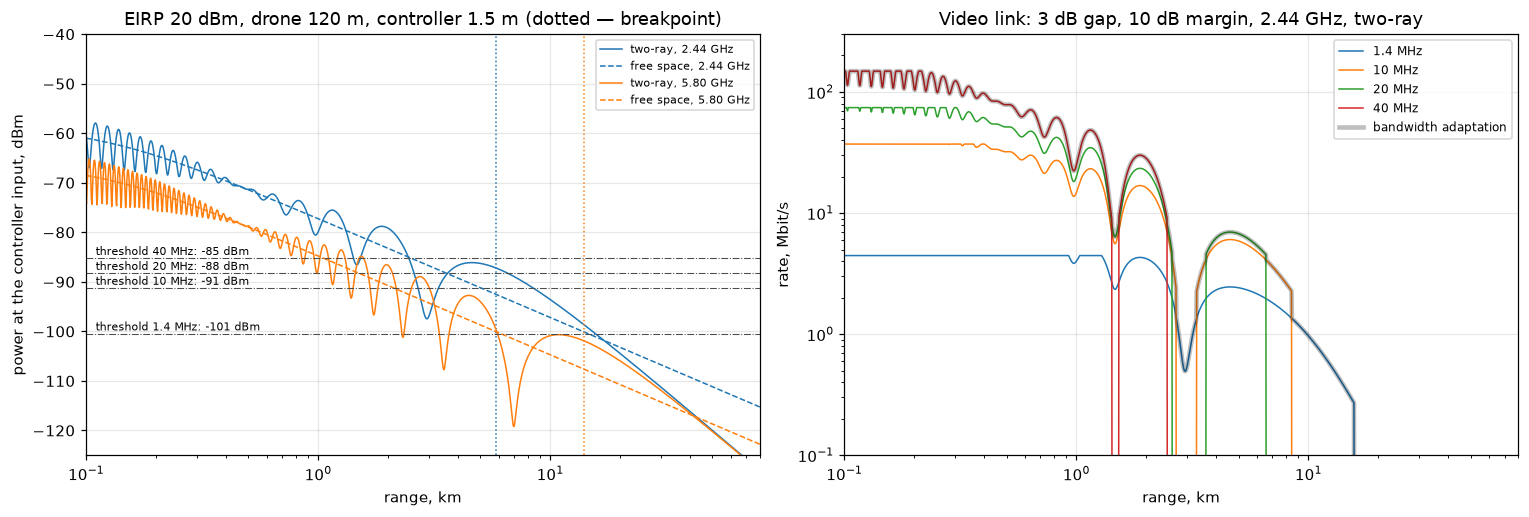

Two-ray breakpoint d_b = 4·h_t·h_r/λ: 5.9 km (2.44 GHz), 13.9 km (5.8 GHz)
Brewster angle atan(1/√ε) = 14.5° — at a range of 0.47 km; Γ at 1 / 5 / 20 km: -0.35 / -0.82 / -0.95
First Fresnel-zone radius at the middle of a 10 km path: 18 m — a controller at 1.5 m does not clear it

                 EIRP 20 dBm       EIRP 30 dBm
  1.4 MHz           15.7 km           28.7 km
   10 MHz            8.5 km           16.5 km
   20 MHz            6.6 km           13.6 km
   40 MHz            2.5 km           11.2 km
(10 dB margin; radio horizon 4.12·(√h_t+√h_r) = 50 km; the largest range at which the lowest MCS still closes; +10 dB of power buys 10^(10/40) ≈ 1.8× range beyond the breakpoint, not √10 ≈ 3.2×)


In [10]:
EPS_GROUND = 15                                              # relative permittivity of average ground

def gamma_v(d, ht=H_DRONE, hr=H_RC, eps=EPS_GROUND):
    """Fresnel reflection coefficient, vertical polarization: −1 at grazing incidence, ~0 near the Brewster angle."""
    psi = np.arctan((ht + hr) / d); r = np.sqrt(eps - np.cos(psi)**2)
    return (eps * np.sin(psi) - r) / (eps * np.sin(psi) + r)

def path_gain(d, fc, two_ray=True, ht=H_DRONE, hr=H_RC):
    """Path gain: free space or two-ray (direct + ground reflection with Fresnel Γ)."""
    lam = 3e8 / fc; k = 2 * np.pi / lam
    d1 = np.sqrt(d**2 + (ht - hr)**2); d2 = np.sqrt(d**2 + (ht + hr)**2)
    if not two_ray:
        return (lam / (4 * np.pi * d1))**2
    return (lam / (4 * np.pi))**2 * np.abs(np.exp(-1j * k * d1) / d1 + gamma_v(d, ht, hr) * np.exp(-1j * k * d2) / d2)**2

noise_dbm = lambda bw: -174 + 10 * np.log10(bw) + NF_DB
SC_BW = {1.4: 72, 10: 600, 20: 1200, 40: 2400}              # occupied 15 kHz subcarriers
REQ_DB = REQ["awgn"]                                         # DroneID burst threshold from section 6
GAP_DB, ETA_MAX, OVH = 3.0, 5.5, 0.75                        # gap to Shannon, 64QAM cap, overhead
MARGIN_DB = 10                                               # margin: fading, polarization, airframe, interference
d = np.logspace(2, np.log10(80e3), 1500)

fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
for i, f in enumerate((FC_GHZ * 1e9, 5.8e9)):
    ax[0].semilogx(d / 1e3, EIRP_DBM + G_RX_DBI + 10 * np.log10(path_gain(d, f)), f"C{i}", lw=1, label=f"two-ray, {f/1e9:.2f} GHz")
    ax[0].semilogx(d / 1e3, EIRP_DBM + G_RX_DBI + 10 * np.log10(path_gain(d, f, False)), f"C{i}--", lw=1, label=f"free space, {f/1e9:.2f} GHz")
    db = 4 * H_DRONE * H_RC * f / 3e8
    ax[0].axvline(db / 1e3, color=f"C{i}", ls=":", lw=1)
for j, bw in enumerate(SC_BW):
    s = noise_dbm(SC_BW[bw] * DF) + REQ_DB + MARGIN_DB
    ax[0].axhline(s, color="0.3", lw=0.7, ls="-.")
    ax[0].text(0.11, s + 0.7, f"threshold {bw} MHz: {s:.0f} dBm", fontsize=7)
ax[0].set_xlim(0.1, 80); ax[0].set_ylim(-125, -40); ax[0].set_xlabel("range, km"); ax[0].set_ylabel("power at the controller input, dBm")
ax[0].legend(fontsize=7, loc="upper right"); ax[0].set_title(f"EIRP {EIRP_DBM} dBm, drone {H_DRONE} m, controller {H_RC} m (dotted — breakpoint)")

rates = {}
for j, bw in enumerate(SC_BW):
    B = SC_BW[bw] * DF
    snr = EIRP_DBM + G_RX_DBI + 10 * np.log10(path_gain(d, FC_GHZ * 1e9)) - noise_dbm(B) - MARGIN_DB
    eta = np.minimum(np.log2(1 + 10 ** ((snr - GAP_DB) / 10)), ETA_MAX) * (snr >= REQ_DB)
    rates[bw] = OVH * B * eta / 1e6
    ax[1].loglog(d / 1e3, np.maximum(rates[bw], 1e-3), f"C{j}", lw=1, label=f"{bw} MHz")
env = np.max(np.stack(list(rates.values())), 0)
ax[1].loglog(d / 1e3, np.maximum(env, 1e-3), color="k", lw=3, alpha=0.25, label="bandwidth adaptation")
ax[1].set_xlim(0.1, 80); ax[1].set_ylim(0.1, 300); ax[1].set_xlabel("range, km"); ax[1].set_ylabel("rate, Mbit/s"); ax[1].legend(fontsize=8)
ax[1].set_title(f"Video link: {GAP_DB:.0f} dB gap, {MARGIN_DB} dB margin, {FC_GHZ} GHz, two-ray")
plt.tight_layout(); plt.show()

print(f"Two-ray breakpoint d_b = 4·h_t·h_r/λ: {4*H_DRONE*H_RC*FC_GHZ*1e9/3e8/1e3:.1f} km ({FC_GHZ} GHz), {4*H_DRONE*H_RC*5.8e9/3e8/1e3:.1f} km (5.8 GHz)")
print(f"Brewster angle atan(1/√ε) = {np.degrees(np.arctan(1/np.sqrt(EPS_GROUND))):.1f}° — at a range of {(H_DRONE+H_RC)*np.sqrt(EPS_GROUND)/1e3:.2f} km; Γ at 1 / 5 / 20 km: {gamma_v(1e3):.2f} / {gamma_v(5e3):.2f} / {gamma_v(20e3):.2f}")
print(f"First Fresnel-zone radius at the middle of a 10 km path: {np.sqrt(3e8/(FC_GHZ*1e9)*5e3*5e3/1e4):.0f} m — a controller at {H_RC} m does not clear it")
print(f"\n{'':10}" + "".join(f"{'EIRP ' + str(p) + ' dBm':>18}" for p in (20, 30)))
for bw in SC_BW:
    B = SC_BW[bw] * DF; line = f"{bw:>5} MHz"
    for p in (20, 30):
        ok = p + G_RX_DBI + 10 * np.log10(path_gain(d, FC_GHZ * 1e9)) - noise_dbm(B) - MARGIN_DB >= REQ_DB
        line += f"{d[np.nonzero(ok)[0].max()]/1e3:15.1f} km"
    print(line)
print(f"({MARGIN_DB} dB margin; radio horizon 4.12·(√h_t+√h_r) = {4.12*(np.sqrt(H_DRONE)+np.sqrt(H_RC)):.0f} km; the largest range at which the lowest MCS still closes; +10 dB of power buys 10^(10/40) ≈ 1.8× range beyond the breakpoint, not √10 ≈ 3.2×)")

## 8. ISM: neighbours on the air and frequency hopping
LTE has its own licensed spectrum: the only interference comes from neighbouring cells of the same network, and those can be coordinated (ICIC, power control). OcuSync lives at 2.4 GHz alongside Wi-Fi, Bluetooth and other drones, and it cannot coordinate with any of them. What is left is **frequency hopping** (DroneID changes frequency from burst to burst), **channel selection** from spectrum measurements (the interference graph in the DJI app), and switching between 2.4 and 5.8 GHz.

The model: each session has 3 Wi-Fi networks on random channels 1–13, each busy in a fraction `WIFI_DUTY` of the bursts, with interference 10 dB above the noise. The drone operates 3 dB above the threshold from section 6. The interference hits only part of the 600 subcarriers, so the loss probability is computed with **MIESM**, the same method LTE system simulators use:
$$\gamma_\text{eff}=I^{-1}\!\Big(\frac1{N}\sum_kI(\gamma_k)\Big),$$
where $I$ is the QPSK mutual information and the BLER comes from the section 6 AWGN curve. Strategies: a fixed random channel per session, a random hop every burst, and adaptive selection (listen to the band for 10 bursts, then take the least busy position).

- The **mean** loss is the same for a fixed channel and for hopping: by symmetry both average over the channels in the same way.
- What differs is the **spread**. A fixed channel is either good or stuck under Wi-Fi for the whole session (a bimodal histogram). Hopping turns long outages into rare isolated losses, which an outer erasure code or a retransmission then cleans up: a video frame of 4 packets with a 3-of-4 code is lost noticeably less often.
- **Adaptive selection** wins by orders of magnitude: within 83.5 MHz there is almost always a 10 MHz gap between Wi-Fi networks. Its curve is not monotonic: at a 5–20 % duty cycle a network often fails to "show up" during the 10 sensing bursts, and the drone lands right on it. The $10^{-4}$ level is just the bottom of the measured BLER curve; in practice there are no losses.

Here Wi-Fi activity is independent from burst to burst. In reality it comes in bursts, which only increases the benefit of hopping.

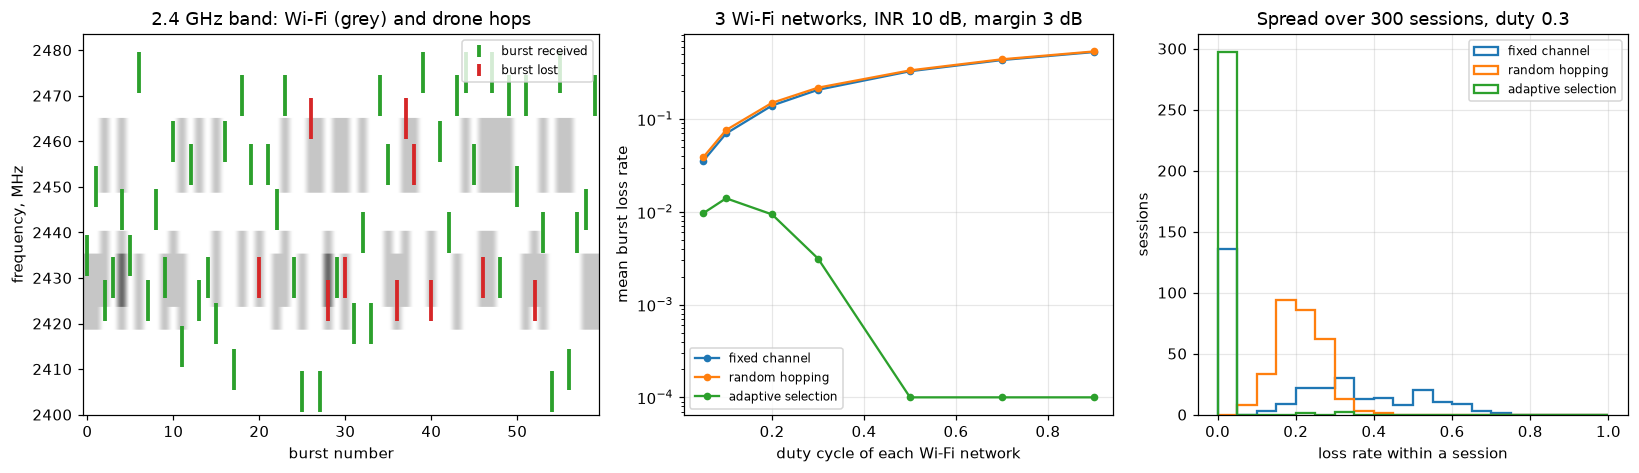

fixed channel         : mean loss 0.204; sessions with > 30 % loss 0.36; loss of a 4-packet video frame with a 3-of-4 erasure code 0.2549
random hopping        : mean loss 0.212; sessions with > 30 % loss 0.06; loss of a 4-packet video frame with a 3-of-4 erasure code 0.1993
adaptive selection    : mean loss 0.003; sessions with > 30 % loss 0.01; loss of a 4-packet video frame with a 3-of-4 erasure code 0.0031


In [11]:
WIFI_BW, INR_DB = 16.6e6, 10                       # occupied band of 20 MHz Wi-Fi; interference above noise when a network transmits
CH = np.arange(2405, 2476, 5) * 1e6                 # 15 positions of a 10 MHz channel within 2400–2483.5 MHz
WIFI_CH = 2412e6 + 5e6 * np.arange(13)             # Wi-Fi channels 1–13
S_SESS, NB, NS = 300, 60, 10                        # sessions, bursts per session, of which used for sensing
OP_DB = REQ["awgn"] + 3                             # operating point: 3 dB above threshold
g_awgn = grid["awgn"]; lb_awgn = np.log10(np.maximum(bler["awgn"], 1e-4))

def bler_lookup(snr_eff):
    """MIESM: effective SNR → BLER from the section 6 AWGN curve"""
    return np.where(snr_eff < g_awgn[0], 1.0, np.where(snr_eff > g_awgn[-1], 1e-4, 10 ** np.interp(snr_eff, g_awgn, lb_awgn)))

def eff_snr(sinr_db):
    """MIESM: average the QPSK mutual information over subcarriers → back to an equivalent AWGN SNR"""
    mi = np.interp(sinr_db, SNR_TAB, CAP_QPSK).mean(-1)
    return np.interp(mi, CAP_QPSK, SNR_TAB)

def session_sim(duty, rng, n_wifi=3):
    """Each session: n_wifi networks on random channels 1–13, each busy in a fraction duty of bursts (independently)."""
    fw = WIFI_CH[rng.integers(0, 13, (S_SESS, n_wifi))]
    act = rng.random((S_SESS, NB, n_wifi)) < duty
    def per(ch):                                     # ch (S, NB) → loss probability of each burst
        f = CH[ch][..., None] + SC_IDX * DF          # (S, NB, 600)
        hit = np.abs(f[..., None] - fw[:, None, None, :]) < WIFI_BW / 2
        I = 10 ** (INR_DB / 10) * np.sum(hit * act[:, :, None, :], -1)
        return bler_lookup(eff_snr(OP_DB - 10 * np.log10(1 + I)))
    fixed = np.repeat(rng.integers(0, len(CH), (S_SESS, 1)), NB, 1)
    hop = rng.integers(0, len(CH), (S_SESS, NB))
    f_all = CH[:, None] + SC_IDX * DF                 # sensing: mean fraction of hit subcarriers over the first NS bursts
    load = np.einsum("swc,sw->sc", (np.abs(f_all[None, :, :, None] - fw[:, None, None, :]) < WIFI_BW / 2).mean(2).transpose(0, 2, 1),
                     act[:, :NS].mean(1))
    adapt = np.repeat(np.argmin(load, 1)[:, None], NB, 1)
    return {k: per(c)[:, NS:] for k, c in (("fixed channel", fixed), ("random hopping", hop),
                                         ("adaptive selection", adapt))}, fw, act, hop

duties = np.array([0.05, 0.1, 0.2, 0.3, 0.5, 0.7, 0.9])
curves = {}
for dty in duties:
    for k, p in session_sim(dty, np.random.default_rng(7))[0].items():
        curves.setdefault(k, []).append(p.mean())
res, fw, act, hop = session_sim(WIFI_DUTY, np.random.default_rng(8))

fig, ax = plt.subplots(1, 3, figsize=(15, 4.4), gridspec_kw={"width_ratios": [1.2, 1, 1]})
s0 = 0
img = np.zeros((NB, 300)); fgrid = np.linspace(2400e6, 2483.5e6, 300)
for w in range(fw.shape[1]):
    img += act[s0, :, w, None] * (np.abs(fgrid - fw[s0, w]) < WIFI_BW / 2)
ax[0].imshow(img.T, origin="lower", aspect="auto", cmap="Greys", vmin=0, vmax=3, extent=[-0.5, NB - 0.5, 2400, 2483.5])
p_hop = res["random hopping"][s0]
ok = np.r_[np.ones(NS, bool), rng.random(NB - NS) > p_hop]
for m, c, lab in ((ok, "C2", "burst received"), (~ok, "C3", "burst lost")):
    ax[0].errorbar(np.nonzero(m)[0], CH[hop[s0, m]] / 1e6, yerr=N_SC * DF / 2e6, fmt="none", ecolor=c, elinewidth=2.5, label=lab)
ax[0].set_xlabel("burst number"); ax[0].set_ylabel("frequency, MHz"); ax[0].legend(fontsize=8, loc="upper right")
ax[0].set_title("2.4 GHz band: Wi-Fi (grey) and drone hops"); ax[0].grid(False)
for i, (k, v) in enumerate(curves.items()):
    ax[1].semilogy(duties, v, f"C{i}o-", ms=4, label=k)
ax[1].set_xlabel("duty cycle of each Wi-Fi network"); ax[1].set_ylabel("mean burst loss rate"); ax[1].legend(fontsize=8)
ax[1].set_title(f"3 Wi-Fi networks, INR {INR_DB} dB, margin {OP_DB - REQ['awgn']:.0f} dB")
bins = np.linspace(0, 1, 21)
for i, k in enumerate(res):
    ax[2].hist(res[k].mean(1), bins, histtype="step", lw=1.5, color=f"C{i}", label=k)
ax[2].set_xlabel("loss rate within a session"); ax[2].set_ylabel("sessions"); ax[2].legend(fontsize=8)
ax[2].set_title(f"Spread over {S_SESS} sessions, duty {WIFI_DUTY}")
plt.tight_layout(); plt.show()

for k, p in res.items():
    q = p[:, :48].reshape(S_SESS, 12, 4)
    fail = 1 - (np.prod(1 - q, -1) + sum(q[..., j] * np.prod(np.delete(1 - q, j, -1), -1) for j in range(4)))
    print(f"{k:22}: mean loss {p.mean():.3f}; sessions with > 30 % loss "
          f"{np.mean(p.mean(1) > 0.3):.2f}; loss of a 4-packet video frame with a 3-of-4 erasure code {fail.mean():.4f}")

## Comparison with LTE
| | LTE | OcuSync / DroneID |
|---|---|---|
| Purpose | cellular network: thousands of users, mobility, roaming | a single point-to-point link: drone ↔ controller |
| Spectrum | licensed; only its own, managed interference | 2.4/5.8 GHz ISM, shared with Wi-Fi: hopping, channel selection, band switching |
| Numerology | 15 kHz, 15.36 MHz / 1024, CP 72–80 | **the same** (for 10 MHz) |
| Synchronization | PSS/SSS at network entry, then tracking the base station (±0.05 ppm) | from scratch in every burst: CP + two ZC-601; two 10–20 ppm crystals |
| Reference signals | CRS/DMRS ~5–10 %, interpolation | ZC symbols 22 % (DroneID), full band → DFT denoising |
| Channel | NLoS, Rayleigh (EPA/EVA/ETU), frequency diversity | LoS, Rician + two-ray; almost no frequency diversity → antennas (2T4R in O3) |
| Path loss | Hata/COST: $d^{3.5}$, urban | free space up to $d_b$, then $d^4$ |
| Adaptation | CQI → MCS and number of RBs, decided by the base station | MCS and channel width 1.4…40 MHz to suit range |
| Code | turbo (4G) / LDPC (5G NR) + HARQ | **the same LTE turbo code** and rate matching; DroneID is one burst without retransmission, repeats inside the burst |
| Multiple access | OFDMA over resource blocks | none: one controller, one drone; neighbours are separated in frequency |
| Power | phone 23 dBm, base station 43–46 dBm | 20 dBm (CE) … ~30 dBm (FCC) EIRP |
| Latency | HARQ RTT 8 ms, tens of ms to a server | video: ~30 ms for the O3 FPV version, 100–200 ms for camera drones (per DJI) |

Links to the rest of the series: the LTE scrambler and CRS are built from the same Gold sequences as the CDMA codes (`cdma_sim`). The root-600 ZC is a discrete chirp, a cousin of the LoRa symbol (`lora_sim`), with the same time ↔ frequency coupling. The decoder is the turbo code from `turbo_sim` and `lte_sim`, and LDPC (`ldpc_sim`) replaced it in 5G for the same reasons that will probably push DJI to switch eventually too.

DroneID was meant as DJI's own version of Remote ID. After NDSS 2023 it became known that it is not encrypted (the pilot's position can be read with a ~$50 SDR), and newer firmware encrypts the payload. The physical layer is unchanged by this. Standard Remote ID (FAA/EU) is sent in Wi-Fi and Bluetooth beacons.

## Things to try
- `K_RICE_DB = 0` — air-to-ground becomes flat Rayleigh: the section 6 curve gets even shallower, and at 1 % BLER EVA beats it by many dB. `K_RICE_DB = 20` — nearly AWGN
- `CFO_HZ = 70e3` — more than the `Q = 4` search covers (±60 kHz): the receiver misses by a whole subcarrier and the CRC fails at any SNR. Increasing `Q` in `int_cfo` fixes it
- make `syms=(3,)` the default in `int_cfo` (ZC-600 only) — the section 6 full receiver starts losing bursts even at high SNR: neighbouring hypotheses $q$ are indistinguishable
- `KEEP = None` (no DFT denoising) — the section 6 full receiver loses ~2 dB: at SNR around 0 dB the noise of the raw LS estimate wrecks the LLRs
- `H_RC = 5` (controller on a mast) — the section 7 breakpoint moves out 3.3×, and every bandwidth reaches farther
- `FC_GHZ = 5.8` — 7.5 dB worse before the breakpoint, almost no difference after it (beyond the breakpoint $G$ does not depend on $\lambda$)
- `EPS_GROUND = 80` (sea) — the Brewster angle drops to 6°, and the pattern of nulls in section 7 shifts
- `EIRP_DBM = 30` — FCC mode: beyond the breakpoint +10 dB buys only ×1.8 range
- `WIFI_DUTY = 0.7` — without adaptation more than half of the bursts are lost; adaptive selection still finds a gap
- `TURBO_ITERS = 2` — the section 6 threshold moves about 1 dB to the right